# Глубинное обучение 1 / Введение в глубинное обучение, ФКН ВШЭ

## Домашнее задание 2: сверточный классификатор.

### Общая информация

Оценка после штрафа после мягкого дедлайна вычисляется по формуле $M_{\text{penalty}} = M_{\text{full}} \cdot 0.85^{t/1440}$, где $M_{\text{full}}$ — полная оценка за работу без учета штрафа, а $t$ — время в минутах, прошедшее после мягкого дедлайна (округление до двух цифр после запятой). Таким образом, спустя первые сутки после мягкого дедлайна вы не можете получить оценку выше 8.5, а если сдать через четыре дня после мягкого дедлайна, то ваш максимум — 5.22 балла.

### Оценивание и штрафы

Максимально допустимая оценка за работу — 10 баллов (+бонусы). Сдавать задание после указанного срока сдачи нельзя.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов. Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке. Также оценка может быть снижена за плохо читаемый код и плохо оформленные графики. Все ответы должны сопровождаться кодом или комментариями о том, как они были получены.

### Правила экспериментов

- В ячейке ниже вычисляется `STUDENT_ID`, не забудьте изменить значение по умолчанию в ней! При запуске обучения используйте сиды `STUDENT_ID`, `STUDENT_ID + 1`, `STUDENT_ID + 2`.
- Ответы должны интерпретировать *ваши* графики и таблицы. Ответы, в которых нет ссылок на ваши числа, оцениваются в 0 баллов. Помимо кода, оцениваются оформление графиков (подписи осей, легенда) и таблиц.

### Технические требования

- Для выполнения задания нужна GPU (достаточно Colab). Ориентировочный суммарный бюджет вычислений — 2–3 часа GPU, планируйте эксперименты заранее.
- Если эксперименты не помещаются в бюджет, увеличьте `batch_size` (128 и больше, при необходимости пересмотрев `lr`), включите `pin_memory` и `persistent_workers` в `DataLoader`, при желании используйте смешанную точность и храните датасет на GPU.

### О задании

В этом задании вам предстоит познакомиться со сверточными сетями и их обучением для классификации изображений с использованием библиотеки PyTorch.

In [ ]:
STUDENT_ID = sum((ord(c) for c in "Денисов"))
STUDENT_ID

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2470, 0.2435, 0.2616)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

Обучение занимает много времени, а сессия Colab может сброситься. Поэтому все результаты обучения сохраняем на Google Drive. `run` принимает те же аргументы, что и `train` (плюс имя запуска), и возвращает те же логи. Если запуск с таким именем уже был, она загружает веса в `model` и логи из файла, ничего не обучая. Поэтому ноутбук можно просто запускать сначала. `run_seeds` повторяет `run` на сидах `STUDENT_ID`, `STUDENT_ID + 1`, `STUDENT_ID + 2` (этого требуют правила сравнения). Аргументы у нее те же. Перед каждым сидом она заново инициализирует веса модели (`reset_parameters` у всех слоев) и возвращает оптимизатор и расписание в исходное состояние, поэтому модель, оптимизатор и расписание создаются один раз, как перед `train`. Имя запуска — ключ для сохранения, поэтому разные конфигурации должны иметь разные имена.

In [ ]:
import io
import os
import time
import pickle
import contextlib
import copy
from functools import partial

import pandas as pd
from google.colab import drive

drive.mount('/content/drive')
RESULTS_DIR = '/content/drive/MyDrive/shw02_results'
os.makedirs(RESULTS_DIR, exist_ok=True)

SEEDS = [STUDENT_ID, STUDENT_ID + 1, STUDENT_ID + 2]
results = {}  # имя запуска -> логи, итоговые метрики, время эпохи, веса


def run(name, model, optimizer, n_epochs, train_loader, val_loader, scheduler=None, label_smoothing=0.0):
    """То же, что train, но с сохранением на Drive: повторный запуск с тем же именем не обучает модель заново."""
    path = f'{RESULTS_DIR}/{name}.pkl'
    if os.path.exists(path):
        with open(path, 'rb') as f:
            results[name] = pickle.load(f)
        model.load_state_dict(results[name]['state_dict'])
        print(f'{name}: загружено с диска, val acc = {results[name]["val_acc"]:.4f}')
        return results[name]['logs']

    start = time.time()
    logs = train(model, optimizer, n_epochs, train_loader, val_loader, scheduler, label_smoothing)
    results[name] = {
        'logs': logs,
        'epoch_time': (time.time() - start) / n_epochs,
        'train_acc_last': np.mean(logs[1][-len(train_loader):]),
        'val_acc': logs[3][-1],
        'val_loss': test(model, val_loader)[0],  # без label smoothing, чтобы loss был сравним между запусками
        'state_dict': {k: v.cpu().clone() for k, v in model.state_dict().items()},  # копия: run_seeds потом сбросит веса
    }
    with open(path, 'wb') as f:
        pickle.dump(results[name], f)
    return logs


def run_seeds(name, model, optimizer, n_epochs, train_loader, val_loader, scheduler=None, label_smoothing=0.0, seeds=SEEDS):
    """run на нескольких сидах с одними и теми же объектами: перед каждым сидом веса инициализируются заново."""
    optimizer_state = copy.deepcopy(optimizer.state_dict())  # lr и пустые буферы моментов
    scheduler_state = copy.deepcopy(scheduler.state_dict()) if scheduler is not None else None
    out = []
    for seed in seeds:
        run_name = f'{name}_seed{seed}'
        torch.manual_seed(seed)
        for module in model.modules():
            if hasattr(module, 'reset_parameters'):
                module.reset_parameters()  # в том же порядке, что в __init__: как у модели, созданной с этим сидом
        optimizer.load_state_dict(optimizer_state)
        if scheduler is not None:
            scheduler.load_state_dict(scheduler_state)
        with contextlib.redirect_stdout(io.StringIO()):  # не печатаем по 20 эпох на каждый запуск
            run(run_name, model, optimizer, n_epochs, train_loader, val_loader, scheduler, label_smoothing)
        print(f'{run_name}: val acc = {results[run_name]["val_acc"]:.4f}')
        out.append(results[run_name])
    return out


def mean_std(group, key='val_acc'):
    values = [r[key] for r in group]
    return np.mean(values), np.std(values, ddof=1)


def is_better(a, b):
    """a лучше b, только если разница средних val acc больше одного std."""
    (mean_a, std_a), (mean_b, std_b) = mean_std(a), mean_std(b)
    return mean_a - mean_b > max(std_a, std_b)


def results_table(groups, keys=('val_acc', 'val_loss')):
    return pd.DataFrame({name: {key: '%.4f ± %.4f' % mean_std(group, key) for key in keys}
                         for name, group in groups.items()}).T


def plot_val_acc(groups, title=''):
    """Средняя по сидам val accuracy по эпохам с полосой ± std."""
    plt.figure(figsize=(8, 4.5))
    for name, group in groups.items():
        values = np.array([r['logs'][3] for r in group])
        epochs = np.arange(1, values.shape[1] + 1)
        plt.plot(epochs, values.mean(0), label=name)
        plt.fill_between(epochs, values.mean(0) - values.std(0), values.mean(0) + values.std(0), alpha=0.2)
    plt.xlabel('Эпоха')
    plt.ylabel('val accuracy')
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

## 0. Загрузка данных

Работать мы будем с набором данных [CIFAR10](https://www.cs.toronto.edu/~kriz/cifar.html). CIFAR10 представляет собой набор изображений 32х32 пикселя, разделенных на 10 классов.

![title](https://pytorch.org/tutorials/_images/cifar10.png)




Набор данных уже определен в <code>torchvision.datasets</code>, так что возьмем его оттуда.

Функция `get_cifar10_data` ниже использует фиксированный сид `0`. Замените его на значение, зависящее от вашего `STUDENT_ID` (см. правила в начале ноутбука).

In [ ]:
def get_cifar10_data(batch_size, transform_train, transform_eval=None, valid_size=0.3, num_workers=2):
    torch.manual_seed(STUDENT_ID)
    np.random.seed(STUDENT_ID)

    if transform_eval is None:
        transform_eval = transforms.Compose(
            [transforms.ToTensor(),
             transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD)]
        )

    # train и val используют разные transform, чтобы аугментации не попадали в валидацию
    train_dataset_full = torchvision.datasets.CIFAR10(
        root='./data', train=True, download=True, transform=transform_train
    )
    eval_dataset_full = torchvision.datasets.CIFAR10(
        root='./data', train=True, download=True, transform=transform_eval
    )
    testset = torchvision.datasets.CIFAR10(
        root='./data', train=False, download=True, transform=transform_eval
    )

    train_idx, valid_idx = train_test_split(
        np.arange(len(train_dataset_full)),
        test_size=valid_size,
        shuffle=True,
        random_state=STUDENT_ID
    )

    trainset = torch.utils.data.Subset(train_dataset_full, train_idx)
    valset = torch.utils.data.Subset(eval_dataset_full, valid_idx)

    train_loader = torch.utils.data.DataLoader(
        trainset, batch_size=batch_size, shuffle=True, num_workers=num_workers, pin_memory=True
    )
    val_loader = torch.utils.data.DataLoader(
        valset, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True
    )
    test_loader = torch.utils.data.DataLoader(
        testset, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True
    )

    return train_loader, val_loader, test_loader

In [ ]:
transform_train = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD)]
)

transform_eval = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD)]
)

train_loader, val_loader, test_loader = get_cifar10_data(
    batch_size=64,
    transform_train=transform_train,
    transform_eval=transform_eval
)

Files already downloaded and verified
Files already downloaded and verified


Посмотрим на изображения:

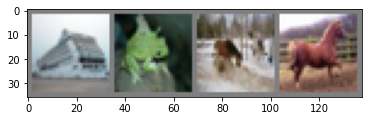

ship frog horse horse


In [ ]:
def imshow(img):
    img = img / 2 + 0.5
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


dataiter = iter(train_loader)
images, labels = next(dataiter)

imshow(torchvision.utils.make_grid(images[:4]))

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')
print(*[classes[labels[i]] for i in range(4)])

## 1. Задание сверточной сети (0.75 балла)

Теперь нам нужно задать сверточную нейронную сеть, которую мы будем обучать классифицировать изображения.

Используем сеть, основанную на одном блоке архитектуры ResNet.

<img src="https://i.ibb.co/2hg962h/basic-block.png" width="500"/>

__Указания:__

- Все сверточные слои должны иметь 32 выходных канала, а также не должны изменять ширину и высоту изображения.
- Выход блока сократите до размерности 32х4х4, применив average pooling.
- Для получения итоговых логитов, распрямите выход пулинга в вектор из 512 элементов, а затем пропустите его через линейный слой.

**Задание 1.1 (0.75 балла).**

Определите архитектуру сети соответственно схеме и указаниям выше.

Ключевые слова: <code>Conv2d</code>, <code>BatchNorm2d</code>, <code>AvgPool2d</code>.

In [ ]:
n_classes = 10


class BasicBlockNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)
        self.shortcut = nn.Conv2d(3, 32, kernel_size=1)  # skip-связь по схеме: 3 канала -> 32
        self.pool = nn.AvgPool2d(kernel_size=8)           # 32x32x32 -> 32x4x4
        self.fc = nn.Linear(32 * 4 * 4, n_classes)

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = F.relu(out + self.shortcut(x))
        out = self.pool(out)
        return self.fc(out.flatten(1))

In [ ]:
net = BasicBlockNet()
net

Проверим, что выход сети имеет корректную размерность:

In [ ]:
assert net(torch.zeros((10, 3, 32, 32))).shape == (10, 10)

Чтобы проводить вычисления на GPU, в PyTorch необходимо руками перекладывать объекты, с которыми вы хотите проводить вычисления, на графический ускоритель. Это делается следующим образрм:

In [ ]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

In [ ]:
net = net.to(device)

Подключение GPU в google.colab:

**Среда выполнения** -> **Сменить среду выполнения** -> **Аппаратный ускоритель** -> **GPU**

## 2. Обучение и тестирование модели (1 балл)

Пара важных замечаний:
- Все сравнения и выбор гиперпараметров делаются по train/val. Тестовая выборка используется только для итоговой отчетности (разделы 6 и 7), но не для выбора модели.
- Здесь и далее любое утверждение вида «стало лучше/хуже» **должно опираться на 3 запуска** с сидами `STUDENT_ID + ...` и сравнение mean ± std. Разница меньше одного std не считается улучшением.

**Задание 2.1 (0.5 балла).** Переходим к обучению модели. Заполните пропуски в функциях `test` и `train_epoch`. В качестве функции потерь будем использовать [кросс-энтропию](https://pytorch.org/docs/stable/generated/torch.nn.functional.cross_entropy.html) (с учетом параметра `label_smoothing`, который понадобится в разделе 3), а в качестве метрики качества accuracy.

In [ ]:
def test(model, loader, label_smoothing=0.0):
    loss_log = []
    acc_log = []
    model.eval()

    with torch.no_grad():
        for data, target in loader:

            data, target = data.to(device), target.to(device)
            logits = model(data)
            loss = F.cross_entropy(logits, target, label_smoothing=label_smoothing)

            loss_log.append(loss.item())

            acc = (logits.argmax(dim=1) == target).float().mean()

            acc_log.append(acc.item())

    return np.mean(loss_log), np.mean(acc_log)


def train_epoch(model, optimizer, train_loader, label_smoothing=0.0):
    loss_log = []
    acc_log = []
    model.train()

    for data, target in train_loader:

        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        logits = model(data)
        loss = F.cross_entropy(logits, target, label_smoothing=label_smoothing)
        loss.backward()
        optimizer.step()

        loss_log.append(loss.item())

        acc = (logits.argmax(dim=1) == target).float().mean()

        acc_log.append(acc.item())

    return loss_log, acc_log


def train(model, optimizer, n_epochs, train_loader, val_loader, scheduler=None, label_smoothing=0.0):
    train_loss_log, train_acc_log, val_loss_log, val_acc_log = [], [], [], []

    for epoch in range(n_epochs):
        train_loss, train_acc = train_epoch(model, optimizer, train_loader, label_smoothing=label_smoothing)
        val_loss, val_acc = test(model, val_loader, label_smoothing=label_smoothing)

        train_loss_log.extend(train_loss)
        train_acc_log.extend(train_acc)

        val_loss_log.append(val_loss)
        val_acc_log.append(val_acc)

        print(f"Epoch {epoch}")
        print(f" train loss: {np.mean(train_loss)}, train acc: {np.mean(train_acc)}")
        print(f" val loss: {val_loss}, val acc: {val_acc}\n")

        if scheduler is not None:
            scheduler.step()

    return train_loss_log, train_acc_log, val_loss_log, val_acc_log

Запустим обучение модели. В качестве оптимизатора для базового запуска будем использовать стохастический градиентный спуск с моментом.

__Замечание:__ Для достижения наилучшего качества в нашем случае потребуется обучать модель несколько сотен эпох. Однако в целях экономии вашего времени и сил, пока мы ограничимся 20 эпохами (если в условии не сказано иное).

In [ ]:
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
train_loss_log, train_acc_log, val_loss_log, val_acc_log = run('2.1_sgd_lr0.1', net, optimizer, 20, train_loader, val_loader)

Посчитайте метрики на валидационной выборке:

In [ ]:
val_loss, val_acc = test(net, val_loader)
print(f'Validation: loss = {val_loss:.4f}, accuracy = {val_acc:.4f}')

Для базовой реализации ожидаем validation accuracy $\geqslant0.67$.

**Задание 2.2 (0.5 балла).** Постройте графики зависимости функции потерь и точности классификации от номера шага оптимизатора. На каждом графике расположите данные и для обучающей и для валидационной выборки, итого у вас должно получиться два графика. Обратите внимание, что на обучающей выборке эти данные считаются по каждому батчу, на валидационной же они считаются по всей выборке раз в эпоху.

In [ ]:
def plot_history(train_loss_log, train_acc_log, val_loss_log, val_acc_log, title=''):
    """train — значение на каждом батче, val — по всей выборке в конце каждой эпохи."""
    steps_per_epoch = len(train_loss_log) // len(val_loss_log)
    val_steps = steps_per_epoch * np.arange(1, len(val_loss_log) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for ax, train_values, val_values, name in zip(axes, (train_loss_log, train_acc_log),
                                                  (val_loss_log, val_acc_log), ('Loss', 'Accuracy')):
        ax.plot(train_values, alpha=0.4, label='train')
        ax.plot(val_steps, val_values, 'o-', label='val')
        ax.set_xlabel('Шаг оптимизатора')
        ax.set_ylabel(name)
        ax.set_title(f'{title} {name}')
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.show()


plot_history(train_loss_log, train_acc_log, val_loss_log, val_acc_log, title='SGD, lr = 0.1:')

## 3. Оптимизаторы и расписание длины шага (1.5 балла)

С курса "Машинное обучение 1" вы уже должны знать, что сходимость стохастического градиентного спуска мы можем теоретически гарантировать только если будем определенным образом со временем уменьшать длину шага. На практике при обучении нейронных сетей такая техника оказывается очень полезной, однако теоретически обоснованными способами уменьшения длины шага фантазия не ограничивается.

Одним из простейших способов является кусочно постоянная функция: на нескольких фиксированных эпохах уменьшаем длину шага в константу раз. Современные рецепты чаще используют плавные расписания с разогревом (warmup) в начале обучения.

In [ ]:
net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[10, 15], gamma=0.1)
tr_loss_log, tr_acc_log, val_loss_log, val_acc_log = run('3_sgd_multistep', net, optimizer, 20, train_loader, val_loader, scheduler)

Посчитайте метрики на валидационной выборке для этой конфигурации:

In [ ]:
val_loss, val_acc = test(net, val_loader)
print(f'Validation: loss = {val_loss:.4f}, accuracy = {val_acc:.4f}')

**Задание 3.1 (0.25 балла).** Здесь может возникнуть вопрос: а что будет, если мы не будем уменьшать длину шага в процессе обучения, а сразу возьмем констатную, равную значению нашей кусочно-постоянной функции на последних эпохах, то есть $0.001$ в нашем случае. Запустите обучение и сравните с `MultiStepLR` по val. Получилось лучше / хуже?

In [ ]:
net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[10, 15], gamma=0.1)
res_multistep = run_seeds('basic_sgd_lr0.1_multistep', net, optimizer, 20, train_loader, val_loader, scheduler)

net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)
res_const = run_seeds('basic_sgd_lr0.001_const', net, optimizer, 20, train_loader, val_loader)

groups_31 = {'MultiStepLR (0.1 → 0.01 → 0.001)': res_multistep, 'постоянный lr = 0.001': res_const}
display(results_table(groups_31))
print('MultiStepLR лучше больше чем на 1 std:', is_better(res_multistep, res_const))
plot_val_acc(groups_31, '3.1')

**Вывод** (⚠ подставить числа): val acc с MultiStepLR — ⟨… ± …⟩, с постоянным lr = 0.001 — ⟨… ± …⟩. Постоянный маленький шаг ⟨хуже⟩: за 20 эпох с lr = 0.001 сеть не успевает дойти до хорошей области, и val accuracy растет медленно. MultiStepLR первые 10 эпох быстро продвигается с большим шагом, а потом уменьшает его и «доводит» решение, подавляя шум SGD.

**Задание 3.2 (0.5 балла).** Изучите, какие способы изменения длины шага представлены в `torch.optim.lr_scheduler`. Обязательно рассмотрите:

- `OneCycleLR`;
- косинусное убывание (`CosineAnnealingLR`) с линейным разогревом в первые эпохи (разогрев и основную часть можно объединить, например, через `SequentialLR`).

Для каждого расписания объясните, как оно устроено, постройте график длины шага от номера шага оптимизатора и сравните качество на val с `MultiStepLR`. Обратите внимание, что разные расписания рассчитаны на вызов `scheduler.step()` с разной частотой (раз в эпоху или раз в батч); при необходимости измените функцию `train`.

**Как устроены расписания.**

- `OneCycleLR` ([Smith & Topin, 2018](https://arxiv.org/abs/1708.07120)): первые `pct_start = 30%` шагов lr растет от `max_lr / 25` до `max_lr`, затем по косинусу падает почти до нуля (`max_lr / (25 · 10⁴)`). Одновременно момент SGD меняется в противофазе (0.95 → 0.85 → 0.95). Фаза с большим шагом работает как регуляризация, а длинный спуск в конце доводит решение.
- Косинус с разогревом: первые 2 эпохи lr линейно растет от `0.01·lr` до `lr` (`LinearLR`), потом убывает до нуля по формуле $\eta_t = \tfrac12\eta_{\max}\bigl(1+\cos\tfrac{\pi t}{T}\bigr)$ (`CosineAnnealingLR`). Части объединены через `SequentialLR`.

Оба расписания заданы в шагах оптимизатора, поэтому `scheduler.step()` нужно вызывать после каждого батча, а не раз в эпоху. Для этого меняем `train_epoch` и `train`. У всех трех расписаний максимальный lr = 0.1.

In [ ]:
def train_epoch(model, optimizer, train_loader, label_smoothing=0.0, scheduler=None):
    loss_log = []
    acc_log = []
    model.train()

    for data, target in train_loader:
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        logits = model(data)
        loss = F.cross_entropy(logits, target, label_smoothing=label_smoothing)
        loss.backward()
        optimizer.step()
        if scheduler is not None:
            scheduler.step()

        loss_log.append(loss.item())
        acc_log.append((logits.argmax(dim=1) == target).float().mean().item())

    return loss_log, acc_log


def train(model, optimizer, n_epochs, train_loader, val_loader, scheduler=None, label_smoothing=0.0):
    train_loss_log, train_acc_log, val_loss_log, val_acc_log = [], [], [], []
    # OneCycleLR и warmup + cosine (SequentialLR) заданы в шагах оптимизатора — шагаем ими после каждого батча
    per_batch = isinstance(scheduler, (optim.lr_scheduler.OneCycleLR, optim.lr_scheduler.SequentialLR))

    for epoch in range(n_epochs):
        train_loss, train_acc = train_epoch(model, optimizer, train_loader, label_smoothing=label_smoothing,
                                            scheduler=scheduler if per_batch else None)
        val_loss, val_acc = test(model, val_loader, label_smoothing=label_smoothing)

        train_loss_log.extend(train_loss)
        train_acc_log.extend(train_acc)

        val_loss_log.append(val_loss)
        val_acc_log.append(val_acc)

        print(f"Epoch {epoch}")
        print(f" train loss: {np.mean(train_loss)}, train acc: {np.mean(train_acc)}")
        print(f" val loss: {val_loss}, val acc: {val_acc}\n")

        if scheduler is not None and not per_batch:
            scheduler.step()

    return train_loss_log, train_acc_log, val_loss_log, val_acc_log


# Расписания на 20 эпох по оптимизатору (нужны и в 3.3). OneCycleLR и SequentialLR шагают на каждом батче
steps_per_epoch = len(train_loader)
warmup_steps = 2 * steps_per_epoch
schedulers = {
    'multistep': lambda opt: optim.lr_scheduler.MultiStepLR(opt, milestones=[10, 15], gamma=0.1),
    # max_lr — lr оптимизатора, чтобы при подборе lr в 3.3 расписание менялось вместе с ним
    'onecycle': lambda opt: optim.lr_scheduler.OneCycleLR(opt, max_lr=opt.param_groups[0]['lr'], epochs=20,
                                                          steps_per_epoch=steps_per_epoch),
    'cosine': lambda opt: optim.lr_scheduler.SequentialLR(opt, [
        optim.lr_scheduler.LinearLR(opt, start_factor=0.01, total_iters=warmup_steps),
        optim.lr_scheduler.CosineAnnealingLR(opt, T_max=20 * steps_per_epoch - warmup_steps),
    ], milestones=[warmup_steps]),
}

# График lr от шага оптимизатора (без обучения: оптимизатор на одном фиктивном параметре)
plt.figure(figsize=(10, 4.5))
for schedule in ('multistep', 'onecycle', 'cosine'):
    opt = optim.SGD([nn.Parameter(torch.zeros(1))], lr=0.1, momentum=0.9)
    scheduler = schedulers[schedule](opt)
    lrs = []
    for step in range(20 * steps_per_epoch):
        lrs.append(opt.param_groups[0]['lr'])
        opt.step()
        if schedule != 'multistep':
            scheduler.step()
        elif (step + 1) % steps_per_epoch == 0:
            scheduler.step()
    plt.plot(lrs, label=schedule)
plt.xlabel('Шаг оптимизатора')
plt.ylabel('lr')
plt.title('Длина шага')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [ ]:
# Зависит от: res_multistep (3.1)
net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
res_onecycle = run_seeds('basic_sgd_lr0.1_onecycle', net, optimizer, 20, train_loader, val_loader,
                         schedulers['onecycle'](optimizer))

net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
res_cosine = run_seeds('basic_sgd_lr0.1_cosine', net, optimizer, 20, train_loader, val_loader,
                       schedulers['cosine'](optimizer))

schedules = {'multistep': res_multistep, 'onecycle': res_onecycle, 'cosine': res_cosine}
display(results_table(schedules))
plot_val_acc(schedules, '3.2')

best_schedule = max(schedules, key=lambda s: mean_std(schedules[s])[0])
print('Лучшее расписание:', best_schedule)
print('Лучше MultiStepLR больше чем на 1 std:', is_better(schedules[best_schedule], res_multistep))

**Вывод** (⚠ подставить числа): MultiStepLR — ⟨…⟩, OneCycleLR — ⟨…⟩, warmup + cosine — ⟨…⟩. Лучшее — ⟨…⟩; преимущество над MultiStepLR ⟨больше / меньше⟩ одного std. Плавные расписания уменьшают шаг без резких скачков и в конце опускают lr почти до нуля.

**Задание 3.3 (0.75 балла).** Сравните оптимизаторы `SGD` (с моментом) и `AdamW` и исследуйте влияние `weight_decay` и `label_smoothing`. Используйте лучшее расписание из 3.2 для обоих оптимизаторов.

1. Подберите по val `lr` для каждого оптимизатора на небольшой сетке (например, для `SGD` $\{0.03, 0.1, 0.3\}$, для `AdamW` $\{3 \cdot 10^{-4}, 10^{-3}, 3 \cdot 10^{-3}\}$; на этом шаге достаточно одного запуска на значение).
2. С лучшими `lr` сравните `SGD` и `AdamW` (3 запуска, mean ± std).
3. Для лучшего оптимизатора по очереди (одно изменение за раз) измените `weight_decay` (например, $0$, $10^{-4}$) и `label_smoothing`. Сведите результаты в таблицу.

Параметры `weight_decay` и `label_smoothing` должны быть явными аргументами ваших функций обучения, а не зашитыми константами.

In [ ]:
# Зависит от: schedulers, best_schedule (3.2).
# Шаги 1–2 — без weight decay и label smoothing, чтобы сравнивать только оптимизаторы.
# Запуски SGD с lr = 0.1 совпадают с 3.2 и загрузятся с диска.
optimizers = {'sgd': partial(optim.SGD, momentum=0.9), 'adamw': optim.AdamW}
lr_grid = {'sgd': [0.03, 0.1, 0.3], 'adamw': [3e-4, 1e-3, 3e-3]}
lr_search = {}
for opt in lr_grid:
    for lr in lr_grid[opt]:
        net = BasicBlockNet().to(device)
        optimizer = optimizers[opt](net.parameters(), lr=lr)
        lr_search[(opt, lr)] = run_seeds(f'basic_{opt}_lr{lr}_{best_schedule}', net, optimizer, 20, train_loader,
                                         val_loader, schedulers[best_schedule](optimizer), seeds=[STUDENT_ID])[0]
display(pd.DataFrame([{'оптимизатор': opt, 'lr': lr, 'val acc': r['val_acc']}
                      for (opt, lr), r in lr_search.items()]))
best_lr = {opt: max(lr_grid[opt], key=lambda lr: lr_search[(opt, lr)]['val_acc']) for opt in lr_grid}
print('Лучшие lr:', best_lr)

In [ ]:
# Зависит от: best_schedule (3.2), best_lr (ячейка выше)
res_opt = {}
for opt in ('sgd', 'adamw'):
    net = BasicBlockNet().to(device)
    optimizer = optimizers[opt](net.parameters(), lr=best_lr[opt])
    res_opt[opt] = run_seeds(f'basic_{opt}_lr{best_lr[opt]}_{best_schedule}', net, optimizer, 20, train_loader,
                             val_loader, schedulers[best_schedule](optimizer))
display(results_table(res_opt))
plot_val_acc(res_opt, 'SGD vs AdamW')

best_optimizer = max(res_opt, key=lambda opt: mean_std(res_opt[opt])[0])
other = 'adamw' if best_optimizer == 'sgd' else 'sgd'
print(f'Лучший оптимизатор: {best_optimizer}; лучше больше чем на 1 std:', is_better(res_opt[best_optimizer], res_opt[other]))

In [ ]:
# Зависит от: best_schedule (3.2), best_lr, best_optimizer (ячейки выше)
# Рецепт — настройки обучения, которые дальше применяются к другим моделям; тег — его часть в имени запуска
def make_optimizer(model, recipe):
    """Оптимизатор и расписание по рецепту для модели."""
    optimizer = optimizers[recipe['optimizer']](model.parameters(), lr=recipe['lr'], weight_decay=recipe['weight_decay'])
    return optimizer, schedulers[recipe['schedule']](optimizer)


base_tag = f'{best_optimizer}_lr{best_lr[best_optimizer]}_{best_schedule}'
base = dict(optimizer=best_optimizer, lr=best_lr[best_optimizer], schedule=best_schedule, weight_decay=0.0, label_smoothing=0.0)
wd_grid = {'sgd': [1e-4, 5e-4], 'adamw': [1e-2, 5e-2]}[best_optimizer]  # в AdamW затухание умножается на lr
configs = {'базовая (wd = 0, ls = 0)': (base_tag, base)}
configs.update({f'weight_decay = {wd}': (f'{base_tag}_wd{wd}', dict(base, weight_decay=wd)) for wd in wd_grid})
configs['label_smoothing = 0.1'] = (f'{base_tag}_ls0.1', dict(base, label_smoothing=0.1))

# Базовая конфигурация совпадает с запуском выше и загрузится с диска
res_33 = {}
for name, (tag, recipe) in configs.items():
    net = BasicBlockNet().to(device)
    optimizer, scheduler = make_optimizer(net, recipe)
    res_33[name] = run_seeds(f'basic_{tag}', net, optimizer, 20, train_loader, val_loader, scheduler,
                             recipe['label_smoothing'])
for group in res_33.values():
    for r in group:
        r['val_loss_ls'] = r['logs'][2][-1]  # val loss с тем же label smoothing, что при обучении
display(results_table(res_33, keys=('val_acc', 'val_loss', 'val_loss_ls')))

# Итоговый рецепт: лучшая конфигурация, если она лучше базовой больше чем на 1 std
best_name = max(res_33, key=lambda name: mean_std(res_33[name])[0])
if not is_better(res_33[best_name], res_33['базовая (wd = 0, ls = 0)']):
    best_name = 'базовая (wd = 0, ls = 0)'
best_tag, best_recipe = configs[best_name]
print('Итоговый рецепт:', best_name, best_recipe)

Ответьте на вопросы к заданию 3.3 (со ссылками на ваши числа):

1. Зачем нужен разогрев (warmup) и почему он особенно важен для `AdamW`?
2. Чем `weight_decay` в `AdamW` отличается от L2-регуляризации в `SGD`?
3. Как изменились val accuracy и val loss при `label_smoothing`? Можно ли сравнивать значения loss между запусками с разным `label_smoothing`?
4. Какой оптимизатор оказался лучше, и насколько надежен этот вывод?

1. **Разогрев.** В начале обучения веса случайные, градиенты большие и быстро меняют направление, статистики BatchNorm еще не устоялись. Большой шаг в этот момент может выбросить сеть в плохую область, а разогрев дает начать с маленьких шагов. Для AdamW это особенно важно: шаг равен $\text{lr}\cdot\hat m_t/(\sqrt{\hat v_t}+\varepsilon)$, а оценка $\hat v_t$ по первым батчам очень шумная, поэтому для части весов эффективный шаг огромен ([Liu et al., 2019](https://arxiv.org/abs/1908.03265)). ⟨Сослаться на первые эпохи AdamW на графике / большой lr в сетке.⟩
2. **weight_decay в AdamW и L2 в SGD.** L2 добавляет $\lambda w$ к градиенту. В SGD это то же, что затухание весов $w \leftarrow w - \text{lr}\,\lambda w$. В Adam слагаемое $\lambda w$ проходит через деление на $\sqrt{\hat v_t}$, и веса с большими градиентами регуляризуются слабее. В AdamW затухание отделено от адаптивного шага: $w \leftarrow w - \text{lr}\,(\hat m_t/(\sqrt{\hat v_t}+\varepsilon) + \lambda w)$ — одинаково для всех весов. Поэтому типичные значения $\lambda$ у AdamW (10⁻²–10⁻¹) намного больше, чем у SGD.
3. **label_smoothing** (⚠ подставить): val acc ⟨… → …⟩, val loss без сглаживания ⟨… → …⟩, со сглаживанием ⟨… → …⟩. Loss с разным `label_smoothing` сравнивать напрямую нельзя: у сглаженной цели $(1-\varepsilon)\,\text{onehot} + \varepsilon/K$ ненулевая энтропия, и минимум loss растет с $\varepsilon$. Сравнимы только accuracy и loss, посчитанный без сглаживания (колонка `val_loss`).
4. ⟨SGD / AdamW⟩: ⟨… ± …⟩ против ⟨… ± …⟩, разница ⟨больше / меньше⟩ одного std. Надежность ограничена: lr подбирался по одному запуску на грубой сетке, а val — одно фиксированное разбиение.

## 4. Архитектурные эксперименты (2.5 балла)

В этом разделе мы попробуем улучшить базовую архитектуру.

__Общие условия.__ Чтобы различия определялись только архитектурой, все модели обучаем по одному рецепту с лучшим оптимизатором из предыдущего задания с фиксированнами гиперпараметрами, 20 эпох, без дополнительных аугментаций, если не сказано иное.

**Задание 4.1 (0.5 балла). Абляция skip-связи и BatchNorm.**

Сравните четыре варианта базовой сети из раздела 1: (a) полный, (b) без skip-связи, (c) без `BatchNorm2d`, (d) без skip-связи и без `BatchNorm2d`. Варианты должны отличаться только тем, что убрано (одинаковые инициализация, число каналов, сиды).

Для каждого варианта постройте графики train/val loss и accuracy (как в задании 2.2) и сведите val accuracy (по 3 запускам) в таблицу. Для вариантов без BatchNorm можно дополнительно сделать запуск с более подходящим lr. Если модель расходится при фиксированных параметрах оптимизатора, это результат эксперимента, а не ошибка.

In [ ]:
class AblationNet(nn.Module):
    """BasicBlockNet без skip-связи и/или без BatchNorm. Слои создаются в том же порядке, что в BasicBlockNet,
    поэтому при одинаковом сиде веса сверток и линейного слоя совпадают у всех вариантов
    (shortcut есть всегда, а без skip просто не используется)."""

    def __init__(self, skip=True, bn=True):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32) if bn else nn.Identity()
        self.conv2 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(32) if bn else nn.Identity()
        self.shortcut = nn.Conv2d(3, 32, kernel_size=1)  # создаем всегда, чтобы не сдвинуть инициализацию fc
        self.skip = skip
        self.pool = nn.AvgPool2d(kernel_size=8)
        self.fc = nn.Linear(32 * 4 * 4, n_classes)

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.skip:
            out = out + self.shortcut(x)
        out = self.pool(F.relu(out))
        return self.fc(out.flatten(1))


variants = {
    '(a) полный': BasicBlockNet,
    '(b) без skip': lambda: AblationNet(skip=False),
    '(c) без BN': lambda: AblationNet(bn=False),
    '(d) без skip и без BN': lambda: AblationNet(skip=False, bn=False),
}
variant_names = {'(a) полный': 'basic', '(b) без skip': 'noskip', '(c) без BN': 'nobn', '(d) без skip и без BN': 'noskip_nobn'}

In [ ]:
# Зависит от: best_tag, best_recipe (3.3). Вариант (a) совпадает с итоговым запуском 3.3 и загрузится с диска.
res_41 = {}
for name, model_fn in variants.items():
    net = model_fn().to(device)
    optimizer, scheduler = make_optimizer(net, best_recipe)
    res_41[name] = run_seeds(f'{variant_names[name]}_{best_tag}', net, optimizer, 20, train_loader, val_loader,
                             scheduler, best_recipe['label_smoothing'])
display(results_table(res_41, keys=('val_acc', 'val_loss', 'train_acc_last')))
for name, group in res_41.items():
    plot_history(*group[0]['logs'], title=f'{name}:')

In [ ]:
# Дополнительно: варианты без BN с lr в 10 раз меньше. Зависит от: best_tag, best_recipe (3.3).
low_lr_recipe = dict(best_recipe, lr=best_recipe['lr'] / 10)
res_41_low_lr = {}
for name in ('(c) без BN', '(d) без skip и без BN'):
    net = variants[name]().to(device)
    optimizer, scheduler = make_optimizer(net, low_lr_recipe)
    res_41_low_lr[f'{name}, lr = {low_lr_recipe["lr"]:g}'] = run_seeds(
        f'{variant_names[name]}_{best_tag}_lr{low_lr_recipe["lr"]:g}', net, optimizer, 20, train_loader,
        val_loader, scheduler, low_lr_recipe['label_smoothing'])
display(results_table({**res_41, **res_41_low_lr}, keys=('val_acc', 'val_loss', 'train_acc_last')))

Вопросы:

1. Почему BatchNorm позволяет использовать большую длину шага? Опирайтесь на ваши запуски.
2. Различаются ли варианты с skip-связью и без нее больше, чем на один std? Как вы думаете, почему?
3. Чем отличается поведение train loss и val loss в вариантах (a) и (d)?

1. После BatchNorm выход не зависит от масштаба весов предыдущей свертки: $\mathrm{BN}(\alpha W x) = \mathrm{BN}(Wx)$. Поэтому градиент по $W$ обратно пропорционален $\|W\|$, и слишком большой шаг, увеличивая норму весов, сам себя «гасит». Кроме того, BN не дает активациям расти от слоя к слою и делает ландшафт loss глаже. У нас при lr = ⟨…⟩ варианты с BN дают ⟨…⟩, без BN — ⟨…⟩ (⟨расходится / учится медленнее⟩), а с lr в 10 раз меньше — ⟨…⟩.
2. (a) ⟨… ± …⟩ против (b) ⟨… ± …⟩: ⟨меньше / больше⟩ одного std. В сети всего две свертки, проблемы затухания градиента, которую решают skip-связи в глубоких сетях, здесь нет. Свертка 1×1 в skip — лишь линейный короткий путь от входа.
3. У (a) train loss падает быстрее и ниже, у (d) — медленнее и шумнее: ⟨…⟩. Разрыв train/val ⟨…⟩. Сеть маленькая (~15 тыс. параметров), поэтому обе модели скорее недообучаются, чем переобучаются.

**Задание 4.2 (0.5 балла). Параметры, FLOPs, рецептивное поле.**

1. __Параметры.__ Для каждого варианта из 4.1 выведите число параметров по слоям (покажите вычисление в markdown; не забудьте про параметры `BatchNorm2d`, bias и то, какие из них обучаемые), а затем проверьте результат в коде.
2. __FLOPs.__ Оцените число операций за один прямой проход для одного изображения $3 \times 32 \times 32$: сначала вручную для сверток и линейного слоя (выберите конвенцию — MACs или FLOPs $= 2 \cdot$ MACs — и явно укажите ее), затем проверьте результат в коде. Объясните расхождения, если они есть.
3. __Рецептивное поле.__ Вычислите рецептивное поле одного элемента выхода последнего сверточного слоя базовой сети. Можете использовать рекуррентные формулы: для слоя $l$ с ядром $k_l$ и шагом $s_l$ 
$$r_l = r_{l-1} + (k_l - 1)\, j_{l-1}, \qquad j_l = j_{l-1}\, s_l, \qquad r_0 = j_0 = 1.$$
Затем проверьте ответ экспериментально: например, по тому, на какие пиксели входа зависит выбранный элемент выхода (какая область входа имеет ненулевой градиент). Обоснуйте, почему проверка корректна. Почему эффективное рецептивное поле обычно меньше теоретического?

**Параметры** базовой сети (у сверток есть bias):

| Слой | Формула | Обучаемые |
|---|---|---|
| `conv1`: 3→32, 3×3 | $32\cdot3\cdot9+32$ | 896 |
| `bn1` | $\gamma,\beta$: $2\cdot32$ | 64 (+ необучаемые `running_mean`, `running_var`: 64 и `num_batches_tracked`) |
| `conv2`: 32→32, 3×3 | $32\cdot32\cdot9+32$ | 9 248 |
| `bn2` | $2\cdot32$ | 64 (+ 64) |
| `shortcut`: 3→32, 1×1 | $32\cdot3+32$ | 128 |
| `fc`: 512→10 | $512\cdot10+10$ | 5 130 |
| **Итого** | | **15 530** |

Без skip — 15 402, без BN — 15 402, без skip и BN — 15 274.

**FLOPs** считаем в **MACs** (умножение + сложение = 1 MAC, FLOPs ≈ 2·MACs). Для свертки MACs = $H_{out}W_{out}C_{out}\cdot C_{in}k^2$, для линейного слоя — in·out:

| Слой | Вычисление | MACs |
|---|---|---|
| `conv1` | $32\cdot32\cdot32\cdot3\cdot9$ | 884 736 |
| `conv2` | $32\cdot32\cdot32\cdot32\cdot9$ | 9 437 184 |
| `shortcut` | $32\cdot32\cdot32\cdot3$ | 98 304 |
| `fc` | $512\cdot10$ | 5 120 |
| **Итого** | | **10 425 344 ≈ 10.4 M MACs** |

Без skip — 10 327 040. Буду проверять через `FlopCounterMode` из PyTorch, а он считает только свертки и матричные умножения, так что должен получиться ровно 2 × 10 425 344 (BatchNorm, ReLU, сложение, bias и пулинг — поэлементные операции порядка $32^3$ каждая, в сумме очень мало по сравнению с другими, поэтому их не считаю)

**Рецептивное поле.** `conv1` (k = 3, s = 1): $r = 1 + 2 = 3$; `conv2`: $r = 3 + 2 = 5$. Skip-ветка 1×1 дает поле 1, поэтому ответ — **5×5**. После `AvgPool2d(8)`: $5 + 7 = 12$.

**Проверка.** Берем вход глобального пулинга (выход последней свертки после ReLU) и считаем градиент его центрального элемента по входному изображению. Пиксели вне рецептивного поля на этот элемент не влияют, и градиент по ним ровно 0. Внутри поля градиент может случайно обнулиться из-за ReLU, поэтому объединяем результат по нескольким случайным входам. Модель — в режиме `eval`: в `train` BatchNorm нормирует по статистикам всего батча, и выход формально зависит от всех пикселей.

**Почему эффективное поле меньше теоретического:** через центр поля проходит намного больше путей от входа к выходу, чем через края, и вклад пикселей похож на гауссиану ([Luo et al., 2016](https://arxiv.org/abs/1701.04128)). Это видно на карте градиента ниже.

In [ ]:
from torch.utils.flop_counter import FlopCounterMode


def count_macs(model, size=32):
    """MACs сверток и линейных слоев за один прямой проход одного изображения."""
    macs = {}

    def hook(module, inputs, output):
        if isinstance(module, nn.Conv2d):
            macs[module] = output.numel() * module.in_channels // module.groups * module.kernel_size[0] * module.kernel_size[1]
        else:
            macs[module] = output.numel() * module.in_features

    names = {m: n for n, m in model.named_modules()}
    handles = [m.register_forward_hook(hook) for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, 3, size, size, device=next(model.parameters()).device))
    for h in handles:
        h.remove()
    return pd.Series({names[m]: v for m, v in macs.items()})


def receptive_field(layers):
    """layers — (kernel, stride) слоев на самом длинном пути от входа к выходу."""
    r, j = 1, 1
    for k, s in layers:
        r, j = r + (k - 1) * j, j * s
    return r


def empirical_rf(model, size=32, n_trials=8):
    """Размер области входа с ненулевым градиентом центрального элемента входа model.pool."""
    features = {}
    handle = model.pool.register_forward_hook(lambda module, inputs, output: features.update(map=inputs[0]))
    model.eval()
    grad_sum = torch.zeros(size, size)
    for _ in range(n_trials):
        x = torch.randn(1, 3, size, size, device=device, requires_grad=True)
        model(x)
        h, w = features['map'].shape[-2:]
        grad, = torch.autograd.grad(features['map'][0, :, h // 2, w // 2].sum(), x)
        grad_sum += grad.abs().sum(dim=1)[0].cpu()
    handle.remove()
    rows, cols = (grad_sum > 0).any(dim=1).nonzero(), (grad_sum > 0).any(dim=0).nonzero()
    return (rows.max() - rows.min() + 1).item(), (cols.max() - cols.min() + 1).item(), grad_sum


# Зависит от: variants (4.1)
for name, model_fn in variants.items():
    model = model_fn().to(device)
    params = pd.DataFrame([(n, p.numel()) for n, p in model.named_parameters()], columns=['параметр', 'число'])
    buffers = sum(b.numel() for b in model.buffers())
    macs = count_macs(model)
    model.eval()
    with torch.no_grad(), FlopCounterMode(display=False) as counter:
        model(torch.zeros(1, 3, 32, 32, device=device))
    print(f'\n===== {name} =====')
    display(params.set_index('параметр').T)
    print(f'Обучаемых параметров: {params["число"].sum():,}, буферов BatchNorm: {buffers:,}')
    print(f'MACs по слоям: {dict(macs)}')
    print(f'Итого MACs: {macs.sum():,}; FlopCounterMode: {counter.get_total_flops():,} FLOPs = '
          f'{counter.get_total_flops() // 2:,} MACs')

model = BasicBlockNet().to(device)
rf_h, rf_w, grad_map = empirical_rf(model)
print(f'\nРецептивное поле: теоретическое {receptive_field([(3, 1), (3, 1)])}, экспериментальное {rf_h}x{rf_w}')
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(grad_map > 0, cmap='gray')
axes[0].set_title('Пиксели с ненулевым градиентом')
axes[1].imshow(grad_map[13:20, 13:20] / grad_map.max(), extent=(12.5, 19.5, 19.5, 12.5))
axes[1].set_title('|градиент| около центра')
plt.show()

Вопросы:

1. Какая часть сети содержит больше всего параметров, а какая — больше всего FLOPs?
2. Покрывает ли рецептивное поле базовой сети все изображение $32 \times 32$? Как вы думаете, как это влияет на качество классификации?

1. Больше всего параметров — в `conv2` (9 248 из 15 530, ≈ 60%), еще ≈ 33% — в линейном слое. Больше всего FLOPs — тоже в `conv2` (9.44 M из 10.43 M MACs, ≈ 90%). Линейный слой при трети параметров дает лишь 0.05% FLOPs: его веса используются один раз на изображение, а веса свертки — в каждой из 32×32 позиций.
2. Нет: признаки последней свертки видят окно 5×5 (после пулинга — 12×12). Связать далекие части объекта может только линейный слой поверх грубой сетки 4×4. Поэтому сеть опирается на локальные текстуры и цвета, а не на форму объекта, и это ограничивает качество.

**Задание 4.3 (0.75 балла). Downsampling-блок и малый ResNet.**

Блок из раздела 1 не меняет размер изображения, поэтому его нельзя использовать для постепенного уменьшения разрешения и увеличения числа каналов, как это делается в настоящих ResNet. Для этого нужен блок с downsampling:

- первая свертка $3 \times 3$ имеет `stride=2` и увеличивает число каналов в 2 раза, вторая свертка $3 \times 3$ сохраняет размер;
- после каждой свертки — `BatchNorm2d`, ReLU после сложения с shortcut;
- skip-связь не может быть тождественной (меняются и размер, и число каналов), поэтому в ней используется «проекция» — свертка $1 \times 1$ с тем же `stride=2` и `BatchNorm2d`.

Затем соберите малый ResNet в стиле CIFAR:

- stem: свертка $3 \times 3$ с $C$ каналами, `BatchNorm2d`, ReLU, без пулинга;
- стадия 1: один basic-блок ($C$ каналов);
- стадии 2 и 3: downsampling-блок и один basic-блок, число каналов удваивается на каждой стадии;
- global average pooling и линейный слой.

Число $C$ (например, 32 или 64) выберите сами.

Требования:

1. Проверьте формы выходов блока и сети с помощью `assert` (вход `(N, C, H, W)` → выход `(N, 2C, H/2, W/2)` для downsampling-блока).
2. Посчитайте параметры и FLOPs сети тем же способом, что и в 4.2, и обучите ее по рецепту раздела.
3. Добавьте результаты в сводную таблицу.

In [ ]:
class ResBlock(nn.Module):
    """Basic-блок ResNet: размер и число каналов не меняются, skip-связь тождественная."""

    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(channels)

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + x)


class DownBlock(nn.Module):
    """(N, C, H, W) -> (N, 2C, H/2, W/2), в skip-связи — свертка 1x1 со stride 2 и BatchNorm."""

    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, 2 * channels, 3, stride=2, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(2 * channels)
        self.conv2 = nn.Conv2d(2 * channels, 2 * channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(2 * channels)
        self.shortcut = nn.Sequential(nn.Conv2d(channels, 2 * channels, 1, stride=2, bias=False),
                                      nn.BatchNorm2d(2 * channels))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))


class SmallResNet(nn.Module):
    def __init__(self, c=32):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU())
        self.stage1 = ResBlock(c)
        self.stage2 = nn.Sequential(DownBlock(c), ResBlock(2 * c))
        self.stage3 = nn.Sequential(DownBlock(2 * c), ResBlock(4 * c))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(4 * c, n_classes)

    def forward(self, x):
        out = self.stage3(self.stage2(self.stage1(self.stem(x))))
        return self.fc(self.pool(out).flatten(1))


assert DownBlock(16)(torch.zeros(2, 16, 32, 32)).shape == (2, 32, 16, 16)
assert ResBlock(16)(torch.zeros(2, 16, 32, 32)).shape == (2, 16, 32, 32)
assert SmallResNet()(torch.zeros(2, 3, 32, 32)).shape == (2, 10)

# Зависит от: count_macs, receptive_field, empirical_rf (4.2)
resnet = SmallResNet().to(device)
stages = lambda name: name.split('.')[0]
resnet_table = pd.DataFrame({
    'параметры': pd.Series({n: p.numel() for n, p in resnet.named_parameters()}).groupby(stages).sum(),
    'MACs': count_macs(resnet).groupby(stages).sum(),
})
display(resnet_table)
print(f'Всего: {resnet_table["параметры"].sum():,} параметров, {resnet_table["MACs"].sum():,} MACs')
resnet_path = [(3, 1)] + [(3, 1)] * 2 + [(3, 2)] + [(3, 1)] * 3 + [(3, 2)] + [(3, 1)] * 3
print(f'Рецептивное поле: теоретическое {receptive_field(resnet_path)}, '
      f'экспериментальное {empirical_rf(resnet, size=128)[:2]} (вход 128x128, чтобы поле не обрезалось краями)')

In [ ]:
# Зависит от: best_tag, best_recipe (3.3), res_41 (4.1)
net = SmallResNet().to(device)
optimizer, scheduler = make_optimizer(net, best_recipe)
res_43 = run_seeds(f'small_resnet_{best_tag}', net, optimizer, 20, train_loader, val_loader, scheduler,
                   best_recipe['label_smoothing'])
display(results_table({'BasicBlockNet': res_41['(a) полный'], 'Малый ResNet': res_43},
                      keys=('val_acc', 'val_loss', 'epoch_time')))
plot_history(*res_43[0]['logs'], title='Малый ResNet:')

Вопросы:

1. Зачем в shortcut нужна свертка $1 \times 1$, и почему у нее такой же `stride`, как у основной ветки? Что произойдет, если взять `stride=1`?
2. Как выросли рецептивное поле, число параметров и FLOPs по сравнению с сетью из раздела 1, и как это отразилось на качестве и времени эпохи?
3. На какой стадии сосредоточено больше всего параметров, а на какой — больше всего FLOPs? Почему они совпадают / не совпадают?

1. Выход основной ветки имеет размер 2C × H/2 × W/2, а вход — C × H × W, и сложить их нельзя. Свертка 1×1 — самая дешевая линейная проекция, которая меняет число каналов и не добавляет пространственного контекста. Ее stride должен совпадать со stride основной ветки, иначе не совпадут H и W. При `stride=1` shortcut выдаст 2C × H × W, и сложение упадет с ошибкой размерностей.
2. Рецептивное поле: 5 → 49 (больше изображения). Параметры: 15.5 тыс. → 678 тыс. MACs: 10.4 M → 86.9 M. Качество: ⟨… ± …⟩ против ⟨… ± …⟩, время эпохи: ⟨…⟩ против ⟨…⟩ с.
3. Параметры: stage3 — 78% (526 тыс.), stage2 — 19%, stage1 — 3%. MACs: stage2 и stage3 — по 39% (33.6 M), stage1 — 22%. Не совпадают, потому что параметры свертки ∝ $C_{in}C_{out}k^2$ и не зависят от разрешения, а MACs ∝ $C_{in}C_{out}k^2 HW$. При удвоении каналов и уменьшении стороны вдвое $C^2HW$ не меняется, поэтому вычисления распределены почти равномерно, а параметры растут в 4 раза на каждой стадии.

**Задание 4.4 (0.75 балла). ConvNeXt-подобный блок.**

После ResNet архитектуры сверточных сетей во многом «подтянулись» к трансформерам. Один из примеров — семейство [ConvNeXt](https://arxiv.org/abs/2201.03545). Реализуйте блок в его стиле:

- depthwise-свертка $7 \times 7$ (число групп равно числу каналов, размер изображения не меняется);
- `LayerNorm` по канальной оси (учтите, что в формате NCHW для этого нужна перестановка осей или специальная реализация);
- 1x1 (pointwise) расширение числа каналов в 4 раза;
- активация `GELU`;
- 1x1 сжатие обратно до исходного числа каналов;
- skip-connection (layer scale и stochastic depth реализовывать не нужно).

Соберите сеть с той же макроструктурой, что и в задании 4.3 (stem, три стадии, global average pooling, линейный слой). Между стадиями используйте downsampling в стиле ConvNeXt: `LayerNorm` и свертка $2 \times 2$ со stride 2. Число параметров сети должно отличаться от сети из 4.3 не более чем на 30%. Оптимизатор и `lr` подберите по val (такие сети обычно обучают `AdamW`).

In [ ]:
class LayerNorm2d(nn.LayerNorm):
    """LayerNorm по каналам для тензора NCHW."""

    def forward(self, x):
        return super().forward(x.permute(0, 2, 3, 1)).permute(0, 3, 1, 2)


class ConvNeXtBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dwconv = nn.Conv2d(dim, dim, kernel_size=7, padding=3, groups=dim)
        self.norm = nn.LayerNorm(dim)
        self.pwconv1 = nn.Linear(dim, 4 * dim)  # 1x1-свертка = Linear по каналам в формате NHWC
        self.act = nn.GELU()
        self.pwconv2 = nn.Linear(4 * dim, dim)

    def forward(self, x):
        out = self.dwconv(x).permute(0, 2, 3, 1)  # NCHW -> NHWC
        out = self.pwconv2(self.act(self.pwconv1(self.norm(out))))
        return x + out.permute(0, 3, 1, 2)


class ConvNeXtNet(nn.Module):
    def __init__(self, dims=(32, 64, 128), depths=(2, 2, 4)):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, dims[0], 3, padding=1), LayerNorm2d(dims[0]))
        self.stage1 = nn.Sequential(*[ConvNeXtBlock(dims[0]) for _ in range(depths[0])])
        self.stage2 = nn.Sequential(LayerNorm2d(dims[0]), nn.Conv2d(dims[0], dims[1], 2, stride=2),
                                    *[ConvNeXtBlock(dims[1]) for _ in range(depths[1])])
        self.stage3 = nn.Sequential(LayerNorm2d(dims[1]), nn.Conv2d(dims[1], dims[2], 2, stride=2),
                                    *[ConvNeXtBlock(dims[2]) for _ in range(depths[2])])
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.norm = nn.LayerNorm(dims[2])
        self.fc = nn.Linear(dims[2], n_classes)

    def forward(self, x):
        out = self.stage3(self.stage2(self.stage1(self.stem(x))))
        return self.fc(self.norm(self.pool(out).flatten(1)))


assert ConvNeXtBlock(16)(torch.zeros(2, 16, 32, 32)).shape == (2, 16, 32, 32)
assert ConvNeXtNet()(torch.zeros(2, 3, 32, 32)).shape == (2, 10)

# Ширина как у малого ResNet, глубина (2, 2, 4) подобрана под близкое число параметров
n_convnext = sum(p.numel() for p in ConvNeXtNet().parameters())
n_resnet = sum(p.numel() for p in SmallResNet().parameters())
print(f'ConvNeXt: {n_convnext:,} параметров, малый ResNet: {n_resnet:,}, разница {100 * (n_convnext / n_resnet - 1):+.1f}%')
assert abs(n_convnext / n_resnet - 1) <= 0.3

# Зависит от: count_macs, receptive_field, empirical_rf (4.2)
convnext = ConvNeXtNet().to(device)
display(pd.DataFrame({
    'параметры': pd.Series({n: p.numel() for n, p in convnext.named_parameters()}).groupby(stages).sum(),
    'MACs': count_macs(convnext).groupby(stages).sum(),
}))
convnext_path = [(3, 1)] + [(7, 1)] * 2 + [(2, 2)] + [(7, 1)] * 2 + [(2, 2)] + [(7, 1)] * 4
print(f'MACs: {count_macs(convnext).sum():,}; рецептивное поле: теоретическое {receptive_field(convnext_path)}, '
      f'экспериментальное {empirical_rf(convnext, size=256, n_trials=2)[:2]}')

In [ ]:
# Зависит от: best_tag, best_recipe (3.3), res_43 (4.3). Подбираем оптимизатор и lr по одному сиду, лучший — на трех.
# Расписание и label smoothing — как в рецепте раздела 3, меняем только оптимизатор.
convnext_configs = {'рецепт раздела 3': (best_tag, best_recipe)}
convnext_configs.update({f'AdamW, lr = {lr}, wd = 0.05': (f'{best_tag}_adamw_lr{lr}_wd0.05',
                                                          dict(best_recipe, optimizer='adamw', lr=lr, weight_decay=0.05))
                         for lr in (1e-3, 2e-3, 4e-3)})
search = {}
for name, (tag, recipe) in convnext_configs.items():
    net = ConvNeXtNet().to(device)
    optimizer, scheduler = make_optimizer(net, recipe)
    search[name] = run_seeds(f'convnext_{tag}', net, optimizer, 20, train_loader, val_loader, scheduler,
                             recipe['label_smoothing'], seeds=[STUDENT_ID])[0]
display(pd.Series({name: r['val_acc'] for name, r in search.items()}, name='val acc'))

convnext_tag, convnext_recipe = convnext_configs[max(search, key=lambda name: search[name]['val_acc'])]
net = ConvNeXtNet().to(device)
optimizer, scheduler = make_optimizer(net, convnext_recipe)
res_44 = run_seeds(f'convnext_{convnext_tag}', net, optimizer, 20, train_loader, val_loader, scheduler,
                   convnext_recipe['label_smoothing'])
display(results_table({'Малый ResNet': res_43, 'ConvNeXt': res_44}, keys=('val_acc', 'val_loss', 'epoch_time')))
plot_history(*res_44[0]['logs'], title='ConvNeXt:')

Вопросы:

1. Назовите не менее четырех отличий этого блока от basic-блока ResNet и объясните, какую роль играет каждое.
2. Сопоставьте компоненты блока с блоком трансформера из семинара про ViT: что здесь соответствует перемешиванию информации между «токенами» (пространственными позициями), а что — перемешиванию каналов? Где в трансформере встречаются расширение в 4 раза, `GELU` и `LayerNorm`?
3. Почему в этом блоке используется `LayerNorm`, а не `BatchNorm`? Что изменится при очень малом размере батча?
4. Сравните сети из 4.3 и 4.4 по числу параметров, FLOPs, времени эпохи и качеству. Какая из них эффективнее и почему (с учетом того, что depthwise-свертки плохо загружают GPU)?

1. Отличия от basic-блока ResNet:
   - depthwise-свертка 7×7 вместо плотной 3×3: пространственное смешивание отдельно по каналам; большое ядро дает большое рецептивное поле за $49C$ параметров вместо $9C^2$;
   - inverted bottleneck (1×1 расширение ×4 → GELU → 1×1 сжатие): смешивание каналов в «широком» MLP;
   - LayerNorm вместо BatchNorm и одна нормализация на блок вместо двух: не зависит от батча, одинаково работает в train и eval;
   - GELU вместо ReLU и одна активация на блок;
   - нет активации после сложения: путь $x + f(x)$ остается чисто тождественным;
   - разрешение понижается отдельными слоями (LN + свертка 2×2, stride 2), а не внутри блока.
2. Depthwise-свертка смешивает информацию между пространственными позициями («токенами») — аналог self-attention, но с фиксированными локальными весами. Pointwise 1×1 → GELU → 1×1 смешивает каналы — это MLP блока трансформера, где тоже есть расширение в 4 раза и GELU. LayerNorm в ViT стоит перед attention и перед MLP, residual-связи — вокруг обоих.
3. LayerNorm нормирует каждый объект по его собственным каналам и не зависит от батча, а в train и eval считается одинаково. BatchNorm при очень маленьком батче получает шумные оценки среднего и дисперсии: обучение нестабильно, а `running`-статистики плохо соответствуют обучению. При батче 1 BatchNorm нормирует только по пространству и сильно искажает признаки.
4. Параметры: 690 тыс. против 678 тыс.; MACs: 78.6 M против 86.9 M; качество ⟨… против …⟩; время эпохи ⟨… против …⟩ с. У depthwise-сверток мало вычислений на байт данных: они упираются в память, а не в вычисления GPU, поэтому при меньшем числе FLOPs эпоха может быть не быстрее. Эффективнее ⟨…⟩.

Выведите сводную таблицу по всем архитектурам раздела как в примере. Напоминаем, что все значения — mean ± std по 3 запускам:

| Модель | Параметры | FLOPs (MACs) | Receptive field | val acc | Время эпохи |
|---|---|---|---|---|---|
| Базовая (skip + BN) | | | | | |
| Без skip | | | | | |
| Без BN | | | | | |
| Без skip и без BN | | | | | |
| Малый ResNet | | | | | |
| ConvNeXt-подобная сеть | | | | | |

In [ ]:
# Зависит от: res_41 (4.1), res_43 (4.3), res_44 (4.4), count_macs (4.2), resnet_path, convnext_path
rows = {
    'Базовая (skip + BN)': (res_41['(a) полный'], BasicBlockNet, [(3, 1)] * 2),
    'Без skip': (res_41['(b) без skip'], variants['(b) без skip'], [(3, 1)] * 2),
    'Без BN': (res_41['(c) без BN'], variants['(c) без BN'], [(3, 1)] * 2),
    'Без skip и без BN': (res_41['(d) без skip и без BN'], variants['(d) без skip и без BN'], [(3, 1)] * 2),
    'Малый ResNet': (res_43, SmallResNet, resnet_path),
    'ConvNeXt-подобная сеть': (res_44, ConvNeXtNet, convnext_path),
}
summary = []
for name, (results, model_fn, path) in rows.items():
    model = model_fn().to(device)
    rf = receptive_field(path)
    summary.append({'Модель': name, 'Параметры': f'{sum(p.numel() for p in model.parameters()):,}',
                    'FLOPs (MACs)': f'{count_macs(model).sum() / 1e6:.1f} M', 'Receptive field': f'{rf}×{rf}',
                    'val acc': '%.4f ± %.4f' % mean_std(results),
                    'Время эпохи, с': '%.1f ± %.1f' % mean_std(results, 'epoch_time')})
pd.DataFrame(summary).set_index('Модель')

## 5. Аугментации данных (1.5 балла)

Еще одной стандартной техникой, применяющейся в глубинном обучении, а особенно часто в компьютерном зрении, являются аугментации данных. Суть аугментаций состоит в том, что мы можем некоторым синтетическим образом видоизменять объекты обучающей выборки, тем самым расширяя ее, а также делая итоговую модель более устойчивой к таким изменениям.

Простейшая аугментация, которую можно применить к картинкам — разворот картинки по горизонтальной оси. То есть при обучении модели с вероятностью $0.5$ мы будем разворачивать картинку из обучающей выборки.

In [ ]:
dataiter = iter(train_loader)
images, labels = next(dataiter)

imshow(torchvision.utils.make_grid(images[:4]))

imshow(torchvision.utils.make_grid(transforms.functional.hflip(images[:4])))

Наиболее удобным способом работы с аугментациями в PyTorch является их задание в списке <code>transforms</code>, который затем передается в загрузчик данных. Обучим нашу сеть, применяя горизонтальные повороты:

In [ ]:
transform_train = transforms.Compose(
    [transforms.RandomHorizontalFlip(),
     transforms.ToTensor(),
     transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD)]
)

transform_eval = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD)]
)

train_loader, val_loader, test_loader = get_cifar10_data(
    batch_size=64,
    transform_train=transform_train,
    transform_eval=transform_eval
)

net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4)
scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[10, 15], gamma=0.1)
tr_loss_log, tr_acc_log, val_loss_log, val_acc_log = run(
    '5_flip_sgd_wd0.0001_ls0.05', net, optimizer, 20, train_loader, val_loader, scheduler=scheduler, label_smoothing=0.05
)

Посчитайте метрики на валидационной выборке:

In [ ]:
val_loss, val_acc = test(net, val_loader)
print(f'Validation: loss = {val_loss:.4f}, accuracy = {val_acc:.4f}')

**Задание 5.1 (0.25 балла). Конвейер данных на `torchvision.transforms.v2`.**

Напишите конвейер преобразований на `torchvision.transforms.v2` и сделайте его «базовым»: `RandomCrop(32, padding=4)` и `RandomHorizontalFlip`.Затем измерьте пропускную способность загрузки данных и объясните, где узкое место:

- замерьте время прохода по `train_loader` без модели (изображений в секунду) для разных `num_workers`, с и без `pin_memory`, с и без `persistent_workers`;
- либо перенесите аугментации на GPU (батчевые преобразования применяются к тензору, уже лежащему на GPU) и сравните со вторым вариантом.

Сведите замеры в таблицу и укажите выбранную конфигурацию, которую вы будете использовать дальше.

In [ ]:
import torchvision.transforms.v2 as v2

base_transform = v2.Compose([
    v2.ToImage(),
    v2.RandomCrop(32, padding=4),
    v2.RandomHorizontalFlip(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])
base_dataset = get_cifar10_data(64, base_transform)[0].dataset


def images_per_second(loader, n_epochs=2):
    """Скорость прохода по лоадеру без модели (с переносом на GPU) для каждой эпохи."""
    speeds = []
    for _ in range(n_epochs):
        start, n = time.time(), 0
        for data, target in loader:
            data = data.to(device, non_blocking=True)
            n += len(target)
        torch.cuda.synchronize()
        speeds.append(n / (time.time() - start))
    return speeds


benchmark_path = f'{RESULTS_DIR}/loader_benchmark.pkl'
if os.path.exists(benchmark_path):
    benchmark = pd.read_pickle(benchmark_path)
else:
    rows = []
    for num_workers in (0, 2, 4):
        for pin_memory in (False, True):
            for persistent_workers in ((False, True) if num_workers > 0 else (False,)):
                loader = torch.utils.data.DataLoader(base_dataset, batch_size=64, shuffle=True, num_workers=num_workers,
                                                     pin_memory=pin_memory, persistent_workers=persistent_workers)
                first, second = images_per_second(loader)
                rows.append({'num_workers': num_workers, 'pin_memory': pin_memory,
                             'persistent_workers': persistent_workers,
                             'img/s, эпоха 1': round(first), 'img/s, эпоха 2': round(second)})
    benchmark = pd.DataFrame(rows)
    benchmark.to_pickle(benchmark_path)
print('CPU:', os.cpu_count(), '| GPU:', torch.cuda.get_device_name())
display(benchmark)

best = benchmark.loc[benchmark['img/s, эпоха 2'].idxmax()]
loader_config = dict(num_workers=int(best['num_workers']), pin_memory=bool(best['pin_memory']),
                     persistent_workers=bool(best['persistent_workers']))
print('Дальше используем:', loader_config)


def make_train_loader(transform, batch_size=64, collate_fn=None):
    dataset = get_cifar10_data(batch_size, transform)[0].dataset
    return torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn,
                                       **loader_config)

**Вывод** (⚠ подставить числа). Узкое место — CPU: в Colab всего ⟨2⟩ ядра, и v2-преобразования выполняются для каждой картинки отдельно. Без воркеров получаем ⟨…⟩ img/s, с лучшей конфигурацией ⟨…⟩. Воркеров больше, чем ядер, ставить бесполезно. `pin_memory` немного ускоряет копирование на GPU. `persistent_workers` убирает паузу на запуск воркеров в начале каждой эпохи, что видно по разнице первой и второй эпох. Выбранная конфигурация: ⟨…⟩.

**Задание 5.2 (0.25 балла). `TrivialAugmentWide`, `RandAugment`, `RandomErasing`.**

Изучите эти преобразования в `torchvision.transforms.v2` и в своих словах объясните, как они устроены:

- `TrivialAugmentWide` и `RandAugment`: как выбираются операции и силы их применения, какие параметры есть у `RandAugment`;
- `RandomErasing`: что вырезается, какие параметры (`p`, `scale`, `ratio`) задают его силу, на каком этапе конвейера (до или после `Normalize`) он применяется и почему.

Для каждого преобразования визуализируйте сетку из нескольких аугментированных версий одного и того же изображения.

- **`TrivialAugmentWide`**: для каждой картинки равновероятно выбирается одна операция (сдвиг, поворот, shear, яркость, контраст, цвет, резкость, posterize, solarize, equalize, autocontrast, identity) и случайная сила из 31 уровня в широком диапазоне. Настраивать нечего.
- **`RandAugment`**: последовательно применяются `num_ops` (по умолчанию 2) случайно выбранных операций с одной общей силой `magnitude` (по умолчанию 9 из `num_magnitude_bins = 31`). У операций со знаком (поворот, сдвиг) знак выбирается случайно.
- **`RandomErasing`**: с вероятностью `p` (0.5) вырезается прямоугольник площадью `scale` (0.02–0.33 от изображения) с отношением сторон `ratio` (0.3–3.3) и заливается значением `value` (по умолчанию 0). Ставится после `Normalize`: тогда 0 — это средний цвет датасета, и заливка не сдвигает статистики входа.

In [ ]:
def to_numpy_image(img):
    """Нормализованный тензор (3, H, W) или PIL -> массив для imshow."""
    if not isinstance(img, torch.Tensor):
        return np.asarray(img)
    if img.dtype == torch.uint8:
        return img.permute(1, 2, 0).numpy()
    img = img.cpu() * torch.tensor(CIFAR10_STD).view(3, 1, 1) + torch.tensor(CIFAR10_MEAN).view(3, 1, 1)
    return img.clamp(0, 1).permute(1, 2, 0).numpy()


image, label = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)[0]
to_tensor = [v2.ToImage(), v2.ToDtype(torch.float32, scale=True), v2.Normalize(CIFAR10_MEAN, CIFAR10_STD)]
demo = {
    'TrivialAugmentWide': v2.Compose([v2.ToImage(), v2.TrivialAugmentWide()]),
    'RandAugment': v2.Compose([v2.ToImage(), v2.RandAugment()]),
    'RandomErasing (p=1)': v2.Compose([*to_tensor, v2.RandomErasing(p=1.0)]),
}
fig, axes = plt.subplots(3, 9, figsize=(16, 6))
for row, (name, transform) in zip(axes, demo.items()):
    row[0].imshow(to_numpy_image(image))
    row[0].set_title(f'оригинал\n({classes[label]})', fontsize=9)
    for ax in row[1:]:
        ax.imshow(to_numpy_image(transform(image)))
        ax.set_title(name, fontsize=8)
    for ax in row:
        ax.axis('off')
plt.tight_layout()
plt.show()

**Задание 5.3 (0.5 балла). MixUp и CutMix.**

Эти методы изменяют не только изображения, но и метки. Для пары объектов $(x_i, y_i)$, $(x_j, y_j)$ и $\lambda \sim \mathrm{Beta}(\alpha, \alpha)$:

- MixUp: $\tilde x = \lambda x_i + (1 - \lambda) x_j$, $\tilde y = \lambda y_i + (1 - \lambda) y_j$;
- CutMix: в изображение $x_i$ вставляется прямоугольник из $x_j$, а $\lambda$ равно доле площади, оставшейся от $x_i$; метки смешиваются так же, как в MixUp.

Поскольку $\tilde y$ — вероятностное распределение по классам, для обучения нужна функция потерь с «мягкими» метками
$$\mathcal{L} = -\sum_{k} \tilde y_k \log p_k.$$

Требования:

1. Реализуйте такую функцию потерь самостоятельно и проверьте, что на one-hot метках она совпадает со стандартной кросс-энтропией для жестких меток.
2. Примените MixUp и CutMix к батчам обучающей выборки (можно использовать готовые преобразования из `torchvision.transforms.v2`, но формат и смысл меток вы должны объяснить).
3. Визуализируйте несколько смешанных изображений вместе с их мягкими метками.
4. Обучите модель с каждым из методов, сохраните результаты в таблицу на будущее.

In [ ]:
def soft_cross_entropy(logits, target, label_smoothing=0.0):
    """-sum_k y_k log p_k, среднее по батчу; target — распределения по классам (N, K)."""
    if label_smoothing > 0:
        target = target * (1 - label_smoothing) + label_smoothing / target.shape[1]
    return -(target * F.log_softmax(logits, dim=1)).sum(dim=1).mean()


logits, labels = torch.randn(64, 10), torch.randint(0, 10, (64,))
for ls in (0.0, 0.1):
    ours = soft_cross_entropy(logits, F.one_hot(labels, 10).float(), ls)
    reference = F.cross_entropy(logits, labels, label_smoothing=ls)
    print(f'label_smoothing = {ls}: {ours.item():.6f} vs {reference.item():.6f}')
    assert torch.allclose(ours, reference, atol=1e-6)


def mixup(images, labels, alpha=1.0):
    lam = torch.distributions.Beta(alpha, alpha).sample().item()
    perm = torch.randperm(len(images))
    onehot = F.one_hot(labels, n_classes).float()
    return lam * images + (1 - lam) * images[perm], lam * onehot + (1 - lam) * onehot[perm]


def cutmix(images, labels, alpha=1.0):
    lam = torch.distributions.Beta(alpha, alpha).sample().item()
    perm = torch.randperm(len(images))
    h, w = images.shape[-2:]
    cut_h, cut_w = int(h * (1 - lam) ** 0.5), int(w * (1 - lam) ** 0.5)
    cy, cx = torch.randint(h, (1,)).item(), torch.randint(w, (1,)).item()
    y1, y2 = max(cy - cut_h // 2, 0), min(cy + cut_h // 2, h)
    x1, x2 = max(cx - cut_w // 2, 0), min(cx + cut_w // 2, w)
    images = images.clone()
    images[:, :, y1:y2, x1:x2] = images[perm, :, y1:y2, x1:x2]
    lam = 1 - (y2 - y1) * (x2 - x1) / (h * w)  # реальная доля площади x_i после обрезки краями
    onehot = F.one_hot(labels, n_classes).float()
    return images, lam * onehot + (1 - lam) * onehot[perm]


images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 6, figsize=(16, 6.5))
for row, (name, mix) in zip(axes, (('MixUp', mixup), ('CutMix', cutmix))):
    mixed, soft = mix(images[:6], labels[:6])
    for ax, img, y in zip(row, mixed, soft):
        top = y.argsort(descending=True)[:2]
        ax.imshow(to_numpy_image(img))
        ax.set_title(name + ''.join(f'\n{classes[k]}: {y[k]:.2f}' for k in top if y[k] > 0), fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

Смешивание делаем в `collate_fn` лоадера (так в документации torchvision советуют применять `MixUp`/`CutMix`): лоадер сразу отдает смешанные изображения и мягкие метки — тензор `(N, 10)`, где в строке две ненулевые компоненты λ и 1 − λ, а сумма равна 1. Стандартная `F.cross_entropy` с индексами классов здесь не подходит, поэтому `train_epoch` дорабатываем: для мягких меток считаем `soft_cross_entropy`, а accuracy — по доминирующему классу.

In [ ]:
from torch.utils.data import default_collate


def train_epoch(model, optimizer, train_loader, label_smoothing=0.0, scheduler=None):
    loss_log = []
    acc_log = []
    model.train()

    for data, target in train_loader:
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        logits = model(data)
        if target.ndim == 2:  # мягкие метки после MixUp / CutMix
            loss = soft_cross_entropy(logits, target, label_smoothing)
            target = target.argmax(dim=1)
        else:
            loss = F.cross_entropy(logits, target, label_smoothing=label_smoothing)
        loss.backward()
        optimizer.step()
        if scheduler is not None:
            scheduler.step()

        loss_log.append(loss.item())
        acc_log.append((logits.argmax(dim=1) == target).float().mean().item())

    return loss_log, acc_log


# Зависит от: best_tag, best_recipe (3.3), base_transform и make_train_loader (5.1)
mix_loaders = {
    'MixUp': make_train_loader(base_transform, collate_fn=lambda batch: mixup(*default_collate(batch))),
    'CutMix': make_train_loader(base_transform, collate_fn=lambda batch: cutmix(*default_collate(batch))),
}
res_53 = {}
for name, loader in mix_loaders.items():
    net = BasicBlockNet().to(device)
    optimizer, scheduler = make_optimizer(net, best_recipe)
    res_53[name] = run_seeds(f'basic_base_{name.lower()}_{best_tag}', net, optimizer, 20, loader, val_loader,
                             scheduler, best_recipe['label_smoothing'])
display(results_table(res_53, keys=('val_acc', 'val_loss', 'train_acc_last')))

Вопросы:

1. Как корректно считать accuracy на обучающем батче при смешанных метках и стоит ли ее вообще интерпретировать?
2. Почему val loss и val accuracy считаются по жестким меткам и не используют смешивание?

1. Предсказание можно сравнивать с доминирующим классом $\arg\max \tilde y$ (как у нас) или считать с весами $\lambda[\hat y = y_i] + (1-\lambda)[\hat y = y_j]$. Но интерпретировать такую accuracy как качество подгонки к train не стоит: картинки синтетические, а при λ ≈ 0.5 правильными можно считать оба класса. Поэтому она систематически занижена и не годится для оценки переобучения.
2. Валидация измеряет то, что нужно на самом деле: качество на реальных изображениях с жесткими метками. Смешивание — только регуляризатор обучения. Кроме того, со смешиванием метрики на val были бы случайными (зависели бы от λ и пар) и несравнимыми между запусками.

**Задание 5.4 (0.5 балла). Таблица абляций.**

Постройте таблицу как в примере, где каждая строка — отдельная конфигурация аугментаций, обученная по лучшему рецепту из раздела 3 (3 запуска!):

| Конфигурация | train acc (последняя эпоха) | val acc | val loss | train−val gap |
|---|---|---|---|---|
| Только `RandomHorizontalFlip` | | | | |
| Базовая (crop + flip) | | | | |
| Базовая + `TrivialAugmentWide` | | | | |
| Базовая + `RandAugment` | | | | |
| Базовая + `RandomErasing` | | | | |
| Базовая + MixUp | | | | |
| Базовая + CutMix | | | | |
| Лучшая комбинация | | | | |

Если вычислительные мощности не позволяют, уменьшите число эпох одинаково для всех экпериментов (но не меньше 10) и укажите это.

In [ ]:
# Зависит от: best_tag, best_recipe (3.3), base_transform / make_train_loader (5.1), res_53 (5.3)
# Если не хватает бюджета, уменьшите N_EPOCHS одинаково для всех (не меньше 10).
# Расписания из 3.2 рассчитаны на 20 эпох: при другом N_EPOCHS их нужно пересоздать с новым числом эпох.
N_EPOCHS = 20
after_normalize = lambda *augs: v2.Compose([*base_transform.transforms, *augs])
aug_transforms = {
    'Только RandomHorizontalFlip': v2.Compose([v2.ToImage(), v2.RandomHorizontalFlip(), *to_tensor]),
    'Базовая (crop + flip)': base_transform,
    'Базовая + TrivialAugmentWide': v2.Compose([v2.ToImage(), v2.RandomCrop(32, padding=4), v2.RandomHorizontalFlip(),
                                               v2.TrivialAugmentWide(), *to_tensor]),
    'Базовая + RandAugment': v2.Compose([v2.ToImage(), v2.RandomCrop(32, padding=4), v2.RandomHorizontalFlip(),
                                        v2.RandAugment(), *to_tensor]),
    'Базовая + RandomErasing': after_normalize(v2.RandomErasing()),
}
run_names = dict(zip(aug_transforms, ['basic_flip', 'basic_base', 'basic_base_ta', 'basic_base_ra', 'basic_base_re']))
res_54 = {}
for name, transform in aug_transforms.items():
    net = BasicBlockNet().to(device)
    optimizer, scheduler = make_optimizer(net, best_recipe)
    res_54[name] = run_seeds(f'{run_names[name]}_{best_tag}_ep{N_EPOCHS}', net, optimizer, N_EPOCHS,
                             make_train_loader(transform), val_loader, scheduler, best_recipe['label_smoothing'])
res_54.update({f'Базовая + {name}': group for name, group in res_53.items()})

In [ ]:
# Лучшая комбинация: берем добавки, которые в среднем лучше базовой (если таких меньше двух — две лучшие)
base_mean = mean_std(res_54['Базовая (crop + flip)'])[0]
additions = ['Базовая + TrivialAugmentWide', 'Базовая + RandAugment', 'Базовая + RandomErasing',
             'Базовая + MixUp', 'Базовая + CutMix']
ranked = sorted(additions, key=lambda name: -mean_std(res_54[name])[0])
chosen = [name for name in ranked if mean_std(res_54[name])[0] > base_mean]
# TrivialAugmentWide и RandAugment, MixUp и CutMix взаимоисключающие: оставляем лучший из пары
for pair in (('Базовая + TrivialAugmentWide', 'Базовая + RandAugment'), ('Базовая + MixUp', 'Базовая + CutMix')):
    ranked.remove(max(pair, key=ranked.index))
chosen = [name for name in chosen if name in ranked]
if len(chosen) < 2:
    chosen = ranked[:2]
print('Лучшая комбинация:', chosen)

combo_augs = [v2.ToImage(), v2.RandomCrop(32, padding=4), v2.RandomHorizontalFlip()]
combo_augs += [v2.TrivialAugmentWide()] if 'Базовая + TrivialAugmentWide' in chosen else []
combo_augs += [v2.RandAugment()] if 'Базовая + RandAugment' in chosen else []
combo_augs += to_tensor
combo_augs += [v2.RandomErasing()] if 'Базовая + RandomErasing' in chosen else []
mix = mixup if 'Базовая + MixUp' in chosen else cutmix if 'Базовая + CutMix' in chosen else None
combo_transform = v2.Compose(combo_augs)
combo_loader = make_train_loader(combo_transform, collate_fn=(lambda batch: mix(*default_collate(batch))) if mix else None)
combo_name = 'basic_combo_' + '_'.join(name.split()[-1].lower() for name in chosen)
net = BasicBlockNet().to(device)
optimizer, scheduler = make_optimizer(net, best_recipe)
res_54['Лучшая комбинация'] = run_seeds(f'{combo_name}_{best_tag}_ep{N_EPOCHS}', net, optimizer, N_EPOCHS, combo_loader,
                                        val_loader, scheduler, best_recipe['label_smoothing'])

for group in res_54.values():
    for r in group:
        r['gap'] = r['train_acc_last'] - r['val_acc']
print(f'Эпох: {N_EPOCHS}, рецепт: {best_recipe}')
display(results_table(res_54, keys=('train_acc_last', 'val_acc', 'val_loss', 'gap')))

1. Какие аугментации дали улучшение, превышающее один std, и какие — нет?
2. Где по разрыву train−val видно переобучение, и как его меняют аугментации?
3. Почему сильные аугментации (например, MixUp, CutMix) могут ухудшать качество при коротком обучении в 20 эпох? Подтверждают ли это ваши результаты?

1. (⚠ подставить) Больше чем на один std лучше базовой: ⟨…⟩. В пределах шума или хуже: ⟨…⟩.
2. Переобучение видно по разрыву train − val: без аугментаций (только flip) он ⟨…⟩, с базовыми ⟨…⟩, с сильными ⟨…⟩. Аугментации уменьшают разрыв, но в основном за счет падения train accuracy. Для MixUp/CutMix и сильных аугментаций train accuracy считается на искаженных данных и занижена. Сеть маленькая (~15 тыс. параметров) и скорее недообучается, поэтому разрыв в целом невелик.
3. Сильные аугментации делают задачу на train сложнее. Чтобы это превратилось в лучшую обобщающую способность, нужно больше эпох (и емкости модели): за 20 эпох сеть не успевает выучить даже исходную задачу. MixUp/CutMix к тому же дают «мягкие» цели, что замедляет сходимость. Результаты ⟨подтверждают / не подтверждают⟩: ⟨…⟩.

## 6. Анализ ошибок и интерпретируемость (1.25 балла)

В этом разделе вы проанализируете лучшую модель, выбранную по val из разделов 3–5.

**Задание 6.1 (0.5 балла). Per-class accuracy и confusion matrix.**

1. Посчитайте accuracy по каждому классу на test и постройте confusion matrix (при необходимости нормируйте по строкам).
2. Выведите три наиболее частые пары перепутанных классов.
3. Отдельно разберите пару cat/dog: сколько кошек классифицировано как собаки и наоборот, покажите несколько ошибочно классифицированных изображений этой пары и предложите объяснения.
4. Сравните per-class accuracy вашей лучшей модели с моделью из раздела 1: какие классы улучшились сильнее всего?

In [ ]:
# Зависит от: результатов разделов 3–5 (best_recipe, res_43, res_44, res_54 — при перезапуске ячеек загружаются с диска)
# и 2.1 (модель из раздела 1 — results['2.1_sgd_lr0.1'], ячейка обучения в 2.1).
candidates = {
    'BasicBlockNet (3.3)': (res_33[best_name], BasicBlockNet),
    'Малый ResNet (4.3)': (res_43, SmallResNet),
    'ConvNeXt (4.4)': (res_44, ConvNeXtNet),
    'BasicBlockNet + лучшие аугментации (5.4)': (res_54['Лучшая комбинация'], BasicBlockNet),
}
display(results_table({name: results for name, (results, _) in candidates.items()}))
best_group = max(candidates, key=lambda name: mean_std(candidates[name][0])[0])
best_results, best_model_fn = candidates[best_group]
best_run = max(best_results, key=lambda r: r['val_acc'])
print('Лучшая модель:', best_group)

best_model = best_model_fn().to(device)
best_model.load_state_dict(best_run['state_dict'])
base_model = BasicBlockNet().to(device)
base_model.load_state_dict(results['2.1_sgd_lr0.1']['state_dict'])


def predict(model, loader):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(x.to(device)).argmax(dim=1).cpu() for x, _ in loader]).numpy()


y_test = np.array(test_loader.dataset.targets)
pred_best, pred_base = predict(best_model, test_loader), predict(base_model, test_loader)
print(f'test accuracy: лучшая модель {np.mean(pred_best == y_test):.4f}, модель из раздела 1 {np.mean(pred_base == y_test):.4f}')

cm = confusion_matrix(y_test, pred_best)
per_class = pd.DataFrame({'модель из раздела 1': np.diag(confusion_matrix(y_test, pred_base)) / 1000,
                          'лучшая модель': cm.diagonal() / cm.sum(axis=1)}, index=classes)
per_class['прирост'] = per_class['лучшая модель'] - per_class['модель из раздела 1']
display(per_class.sort_values('прирост', ascending=False).round(3))

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=classes).plot(
    ax=ax, values_format='.2f', cmap='Blues', colorbar=False)
ax.set_title('Confusion matrix на test (по строкам — доли истинного класса)')
plt.show()

errors = cm + cm.T
np.fill_diagonal(errors, 0)
pairs = sorted(((errors[i, j], i, j) for i in range(10) for j in range(i + 1, 10)), reverse=True)[:3]
for total, i, j in pairs:
    print(f'{classes[i]} / {classes[j]}: {total} ошибок ({classes[i]} → {classes[j]}: {cm[i, j]}, обратно: {cm[j, i]})')

CAT, DOG = classes.index('cat'), classes.index('dog')
print(f'\nКошек как собак: {cm[CAT, DOG]}, собак как кошек: {cm[DOG, CAT]}')
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for row, (true, pred) in zip(axes, ((CAT, DOG), (DOG, CAT))):
    for ax, i in zip(row, np.where((y_test == true) & (pred_best == pred))[0][:8]):
        ax.imshow(to_numpy_image(test_loader.dataset[i][0]))
        ax.set_title(f'{classes[true]} → {classes[pred]}', fontsize=9)
    for ax in row:
        ax.axis('off')
plt.tight_layout()
plt.show()

**Выводы** (⚠ подставить): хуже всего распознаются ⟨…⟩, чаще всего путаются ⟨…⟩. Кошек как собак — ⟨…⟩, собак как кошек — ⟨…⟩. Объяснения по картинкам: при 32×32 различающие детали (морда, уши) занимают несколько пикселей, позы и ракурсы сильно варьируются, у кошек и собак похожие окраска и фон (комнаты, диваны). Сильнее всего выросли классы ⟨…⟩: вероятно те, где важна форма объекта, а у лучшей модели рецептивное поле покрывает все изображение.

**Задание 6.2 (0.75 балла). Grad-CAM.**

[Grad-CAM](https://arxiv.org/abs/1610.02391) показывает, какие области изображения повлияли на предсказание класса $c$. Для выбранного сверточного слоя с картами признаков $A^k$ и логита $y^c$ веса каналов равны усредненным по пространству градиентам, $\alpha_k^c = \frac{1}{HW} \sum_{i,j} \frac{\partial y^c}{\partial A^k_{ij}}$, а карта важности — $L^c = \mathrm{ReLU}\bigl(\sum_k \alpha_k^c A^k\bigr)$, которую масштабируют до размера входного изображения и накладывают на него (с прозрачностью).

Требования:

1. Реализуйте Grad-CAM самостоятельно (например, через forward- и backward-хуки на выбранном слое). Использовать готовые библиотеки Grad-CAM нельзя.
2. Объясните, почему вы выбрали именно этот слой.
3. Покажите Grad-CAM не менее чем для 4 правильно и 4 неправильно классифицированных изображений test (среди ошибочных — хотя бы одна пара cat/dog), для предсказанного и истинного классов.
4. Проверьте, что карта действительно зависит от модели: сравните Grad-CAM для одного и того же изображения у модели из раздела 1 и у вашей лучшей модели.

In [ ]:
# Слой — вход глобального пулинга (model.pool), то есть выход последнего сверточного блока: самые «смысловые»
# признаки, у которых еще есть пространственная структура.
def grad_cam(model, x, class_idx):
    saved = {}

    def forward_hook(module, inputs, output):
        saved['A'] = inputs[0]
        inputs[0].register_hook(lambda grad: saved.update(grad=grad))  # backward-хук на картах признаков

    handle = model.pool.register_forward_hook(forward_hook)
    model.eval()
    model.zero_grad()
    model(x)[0, class_idx].backward()
    handle.remove()

    weights = saved['grad'].mean(dim=(2, 3), keepdim=True)  # alpha_k^c
    cam = F.relu((weights * saved['A']).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[0, 0]
    return (cam / (cam.max() + 1e-8)).detach().cpu().numpy()


def show_cam(ax, model, i, class_idx, title):
    x = test_loader.dataset[i][0]
    ax.imshow(to_numpy_image(x))
    ax.imshow(grad_cam(model, x[None].to(device), class_idx), cmap='jet', alpha=0.45)
    ax.set_title(title, fontsize=9)
    ax.axis('off')


# Зависит от: best_model, base_model, pred_best, y_test, CAT, DOG (6.1)
rng = np.random.default_rng(STUDENT_ID)
correct = rng.choice(np.where(pred_best == y_test)[0], 4, replace=False)
wrong = np.where(pred_best != y_test)[0]
cat_dog = wrong[np.isin(y_test[wrong], [CAT, DOG]) & np.isin(pred_best[wrong], [CAT, DOG])][:2]
wrong = np.concatenate([cat_dog, rng.choice(np.setdiff1d(wrong, cat_dog), 4 - len(cat_dog), replace=False)])

fig, axes = plt.subplots(8, 2, figsize=(6, 24))
for row, i in zip(axes, np.concatenate([correct, wrong])):
    pred, true = pred_best[i], y_test[i]
    show_cam(row[0], best_model, i, pred, f'предсказанный: {classes[pred]}')
    show_cam(row[1], best_model, i, true, f'истинный: {classes[true]}')
plt.tight_layout()
plt.show()

# Зависит ли карта от модели: та же картинка у модели из раздела 1 и у лучшей модели
fig, axes = plt.subplots(4, 2, figsize=(6, 12))
for row, i in zip(axes, np.concatenate([correct[:2], wrong[:2]])):
    show_cam(row[0], base_model, i, y_test[i], f'модель из раздела 1: {classes[y_test[i]]}')
    show_cam(row[1], best_model, i, y_test[i], f'лучшая модель: {classes[y_test[i]]}')
plt.tight_layout()
plt.show()

Вопросы к заданию 6.2:

1. На что смотрит модель при правильных и неправильных предсказаниях? Есть ли признаки того, что модель использует фон или контекст?
2. Какие вы видите минусы у такого способа визуализации?

1. (⚠ дописать по своим картинкам) При правильных предсказаниях карта ⟨покрывает сам объект⟩, при ошибках ⟨смещена на фон или на часть объекта, похожую на другой класс⟩. Признаки использования контекста: ⟨у plane/ship — небо и вода, у deer/frog — трава⟩. Модель из раздела 1 дает ⟨другие, более «пятнистые»⟩ карты, то есть визуализация действительно зависит от модели.
2. Минусы: низкое разрешение (у ResNet/ConvNeXt карта 8×8, после растяжения — размытые пятна), зависимость от выбора слоя, из-за ReLU видны только «положительные» свидетельства, усреднение градиентов по пространству теряет информацию, подсвеченная область не обязательно причина предсказания. На картинках 32×32 вывод «объект или фон» во многом субъективен.

## 7. Челлендж (1.5 балла)

Постройте лучшую модель, которую сможете, в рамках ограничений:

- не более 30 эпох;
- не более 10 млн параметров;
- обучение на одной GPU;
- только обучающая часть CIFAR-10 (без внешних данных и предобученных весов);
- модель и гиперпараметры выбираются по val, test используется один раз для итоговой оценки.

Вы сами выбираете архитектуру, оптимизатор, расписание, аугментации и регуляризацию, используя идеи из разделов 3–5 (и любые другие).

Что нужно сдать:

1. __Описание решения__ (0.25 балла): текст / таблицы со всеми компонентами (архитектура, число параметров, число эпох, размер батча, оптимизатор, `lr`-расписание, аугментации, регуляризация) и временем одной эпохи.
2. __Абляции__ (0.5 балла): удалите или замените по очереди не менее трех компонентов вашего рецепта и покажите, как меняется val accuracy (не забываем про 3 запуска для финального решения и для каждой абляции). Укажите хотя бы одну идею, которая не сработала.
3. __Обоснование__ (0.25 балла): для каждого компонента рецепта объясните, почему вы его включили, со ссылкой на числа из абляций.
4. __Итоговое качество__ (0.5 балла): test accuracy (mean ± std). Качество $\geqslant 90\%$ — полный балл; от 85% до 90% — 0.25; ниже 85% — 0 баллов.

**Описание решения**

| Компонент | Выбор |
|---|---|
| Архитектура | ResNet-9 из постов [«How to train your ResNet»](https://myrtle.ai/learn/how-to-train-your-resnet/) (Myrtle.ai): conv 64 → [conv 128, MaxPool, residual 2×conv 128] → [conv 256, MaxPool] → [conv 512, MaxPool, residual 2×conv 512] → global max pool → linear (логиты × 0.125) |
| Параметры | 6 573 130 |
| Эпохи / батч | 24 / 512 |
| Оптимизатор | SGD с моментом 0.9, lr = 0.4, weight decay 5·10⁻⁴ |
| Расписание | OneCycleLR |
| Аугментации | RandomCrop(32, padding = 4), RandomHorizontalFlip, Cutout 8×8 (`RandomErasing` с фиксированным квадратом) |
| Регуляризация | label smoothing 0.2, weight decay, Cutout |
| Время эпохи | ⟨…⟩ с |

In [ ]:
class ConvBN(nn.Sequential):
    def __init__(self, in_channels, out_channels):
        super().__init__(nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
                         nn.BatchNorm2d(out_channels), nn.ReLU())


class Residual(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.body = nn.Sequential(ConvBN(channels, channels), ConvBN(channels, channels))

    def forward(self, x):
        return x + self.body(x)


class ResNet9(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            ConvBN(3, 64),
            ConvBN(64, 128), nn.MaxPool2d(2), Residual(128),
            ConvBN(128, 256), nn.MaxPool2d(2),
            ConvBN(256, 512), nn.MaxPool2d(2), Residual(512),
        )
        self.pool = nn.AdaptiveMaxPool2d(1)
        self.fc = nn.Linear(512, n_classes)

    def forward(self, x):
        return self.fc(self.pool(self.layers(x)).flatten(1)) * 0.125


print(f'Параметров: {sum(p.numel() for p in ResNet9().parameters()):,}')

# Зависит от: base_transform, make_train_loader (5.1), cutmix (5.3)
cutout = v2.RandomErasing(p=1.0, scale=(64 / 1024, 64 / 1024), ratio=(1.0, 1.0))  # квадрат 8x8 среднего цвета
loader_cutout = make_train_loader(v2.Compose([*base_transform.transforms, cutout]), batch_size=512)
loader_no_cutout = make_train_loader(base_transform, batch_size=512)
loader_cutmix = make_train_loader(v2.Compose([*base_transform.transforms, cutout]), batch_size=512,
                                  collate_fn=lambda batch: cutmix(*default_collate(batch)))
# Рецепт: SGD (lr = 0.4, momentum = 0.9, wd = 5e-4), OneCycleLR на 24 эпохи, label smoothing 0.2
experiments_7 = {  # имя запуска, модель, лоадер, label smoothing
    'финальный рецепт': ('resnet9', ResNet9, loader_cutout, 0.2),
    'без label smoothing': ('resnet9_ls0', ResNet9, loader_cutout, 0.0),
    'без Cutout': ('resnet9_nocutout', ResNet9, loader_no_cutout, 0.2),
    'ResNet-9 → малый ResNet (4.3)': ('small_resnet_cutout', SmallResNet, loader_cutout, 0.2),
    'идея: + CutMix': ('resnet9_cutmix', ResNet9, loader_cutmix, 0.2),
}
res_7 = {}
for name, (run_name, model_fn, loader, label_smoothing) in experiments_7.items():
    net = model_fn().to(device)
    optimizer = optim.SGD(net.parameters(), lr=0.4, momentum=0.9, weight_decay=5e-4)
    scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=0.4, epochs=24, steps_per_epoch=len(loader))
    res_7[name] = run_seeds(run_name, net, optimizer, 24, loader, val_loader, scheduler, label_smoothing)
display(results_table(res_7, keys=('val_acc', 'val_loss', 'epoch_time')))
plot_val_acc(res_7, '7: абляции')

**Обоснование** (⚠ подставить числа из таблицы абляций):

- **ResNet-9** вместо малого ResNet: ⟨… против …⟩. Широкие каналы (до 512) и раннее понижение разрешения дают большую емкость при умеренных FLOPs.
- **Label smoothing 0.2**: без него ⟨…⟩. Снижает переуверенность модели, что полезно при коротком обучении с большим lr.
- **Cutout**: без него ⟨…⟩. Заставляет опираться на несколько частей объекта, а не на одну деталь.
- **OneCycleLR**: позволяет взять большой пиковый lr (0.4) и в конце опустить его почти до нуля (сравнение расписаний — в разделе 3).
- **Не сработало:** CutMix — ⟨…⟩: за 24 эпохи сильная регуляризация не окупается (как и в 5.4).

In [ ]:
# Test — один раз, для финального рецепта. Зависит от: res_7 (ячейка выше)
test_accs = []
for r in res_7['финальный рецепт']:
    model = ResNet9().to(device)
    model.load_state_dict(r['state_dict'])
    test_accs.append(test(model, test_loader)[1])
print(f'Test accuracy: {np.round(test_accs, 4).tolist()} -> {np.mean(test_accs):.4f} ± {np.std(test_accs, ddof=1):.4f}')

## Бонус. Логирование в comet (1 балл)

На практике специалиста по глубинному обучению часто встречаются ситуации, когда нейросеть учится на каком-то удаленном сервере. И обычно вам хочется отслеживать прогресс обучения, особенно когда время обучения модели исчисляется днями или неделями. Для таких целей существует несколько инструментов. Например: [TensorBoard](https://docs.pytorch.org/tutorials/recipes/recipes/tensorboard_with_pytorch.html), [comet](https://www.comet.com), [wandb](https://wandb.ai/). Выберите любой удобный из них.

Ваша задача состоит в том, чтобы разобраться как им пользоваться, и повторить задания 2.1 и 2.2 с его использованием. Обучение вы можете запускать в этом же ноутбуке, но теперь вам необходимо логировать значения функции потерь и точности на обучающей выборке и на валидационной. Результатом работы должны быть ваш код, публичная ссылка на страничку с графиками, идентичными графикам в задании 2.2 или выхлоп тензорбоард.

In [ ]:
# Зависит от: train_epoch / test (последние версии), train_loader (1.1), RESULTS_DIR
from torch.utils.tensorboard import SummaryWriter

log_dir = f'{RESULTS_DIR}/tensorboard/sgd_lr0.1'
if not os.path.exists(f'{log_dir}/done'):
    torch.manual_seed(STUDENT_ID)
    model = BasicBlockNet().to(device)
    optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.9)
    writer = SummaryWriter(log_dir)
    step = 0
    for epoch in range(20):
        train_loss, train_acc = train_epoch(model, optimizer, train_loader)
        for loss, acc in zip(train_loss, train_acc):
            writer.add_scalars('loss', {'train': loss}, step)
            writer.add_scalars('accuracy', {'train': acc}, step)
            step += 1
        val_loss, val_acc = test(model, val_loader)
        writer.add_scalars('loss', {'val': val_loss}, step)
        writer.add_scalars('accuracy', {'val': val_acc}, step)
        writer.flush()
    writer.close()
    open(f'{log_dir}/done', 'w').close()

In [ ]:
%load_ext tensorboard
%tensorboard --logdir "{log_dir}"

## Бонус. Качество 94%+ (1 балл)

Если средняя по 3 запускам test accuracy вашей модели не ниже 94% при ограничениях пункта 7, вы получаете 1 дополнительный балл. Бонус засчитывается только при наличии таблицы абляций и воспроизводимого кода.

## Источники

- He et al. [Deep Residual Learning for Image Recognition](https://arxiv.org/abs/1512.03385), 2016.
- Liu et al. [A ConvNet for the 2020s](https://arxiv.org/abs/2201.03545), 2022.
- Smith & Topin. [Super-Convergence](https://arxiv.org/abs/1708.07120), 2018; Loshchilov & Hutter. [AdamW](https://arxiv.org/abs/1711.05101), 2019; Liu et al. [RAdam](https://arxiv.org/abs/1908.03265), 2019.
- Luo et al. [Understanding the Effective Receptive Field](https://arxiv.org/abs/1701.04128), 2016.
- Zhang et al. [mixup](https://arxiv.org/abs/1710.09412), 2018; Yun et al. [CutMix](https://arxiv.org/abs/1905.04899), 2019; DeVries & Taylor. [Cutout](https://arxiv.org/abs/1708.04552), 2017.
- Selvaraju et al. [Grad-CAM](https://arxiv.org/abs/1610.02391), 2017.
- D. Page. [How to train your ResNet](https://myrtle.ai/learn/how-to-train-your-resnet/) (Myrtle.ai) — архитектура ResNet-9 и рецепт раздела 7.